# **DEEP LEARNING**

## **>7 MAIN TASKS<**

1. LOAD AND PREPARE
2. BUILD A NEURAL NETWORK
3. COMPILE MODEL
4. TRAIN MODEL
5. VISUALIZE TRAINING HISTORY
6. EVALUATE MODEL
7. SUMMARIZE

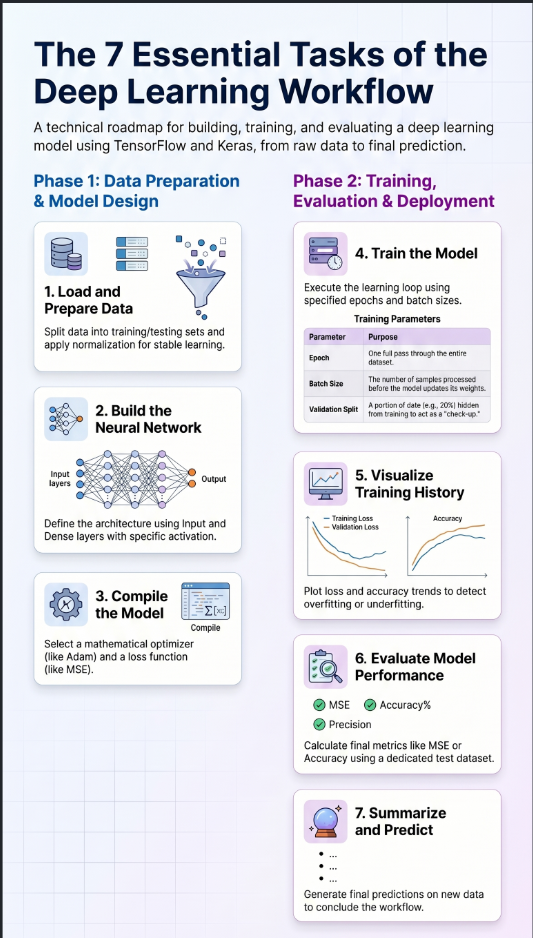

<br>
<br>

# --- MODULE 01: Tensors and Variables ---

### **PART 1: TENSORS**

In [ ]:
import tensorflow as tf

# --- 1. SCALAR (Rank 0 Tensor) ---
# A scalar is a single number with no dimensions.
# dtype = tf.float32 (converts into float)
scaler = tf.constant(3, dtype = tf.float32)
print(f"Scaler: {scaler}")
print(f"Rank (Dimensions): {tf.rank(scaler)}")
print(f"Shape: {scaler.shape}\n")

# --- 2. VECTOR (Rank 1 Tensor) ---
# A vector has one axis (like a list).
# Shape (3,) means 3 elements along one dimension.
vector = tf.constant([1, 2, 3])
print(f"Vector: {vector}")
print(f"Rank: {tf.rank(vector)}")
print(f"Shape: {vector.shape}\n")

# --- 3. MATRIX (Rank 2 Tensor) ---
# A matrix has two axes (Rows and Columns).
# Shape (2, 3) means 2 rows and 3 columns.
matrix = tf.constant([[1, 2, 3],
                      [4, 5, 6]])
print(f"Matrix:\n{matrix}")
print(f"Rank: {tf.rank(matrix)}")
print(f"Shape: {matrix.shape}\n")

# --- 4. TENSOR (Rank 3 Tensor) ---
# A Rank 3 tensor has three axes. Imagine a stack of matrices.
# Shape (2, 2, 3) = 2 matrices, each with 2 rows and 3 columns.
tensor_3d = tf.constant([
    [[1, 2, 3], [4, 5, 6]],
    [[7, 8, 9], [10, 11, 12]]
])
print(f"Rank 3 Tensor:\n{tensor_3d}")
print(f"Rank: {tf.rank(tensor_3d)}")
print(f"Shape: {tensor_3d.shape}")

Scaler: 3.0
Rank (Dimensions): 0
Shape: ()

Vector: [1 2 3]
Rank: 1
Shape: (3,)

Matrix:
[[1 2 3]
 [4 5 6]]
Rank: 2
Shape: (2, 3)

Rank 3 Tensor:
[[[ 1  2  3]
  [ 4  5  6]]

 [[ 7  8  9]
  [10 11 12]]]
Rank: 3
Shape: (2, 2, 3)


In [ ]:
# More ways to generate tensors
# Correction: Use tf.zeros (no 'e') instead of tf.zeroes
tensors = tf.zeros(shape=(2, 3))
print(f"Zeros Tensor:\n{tensors}")

print()

tensors = tf.ones(shape=(2, 3))
print(f"Ones Tensor:\n{tensors}")

print()

tensors = tf.random.normal(shape=(2, 3))
print(f"Random Tensor:\n{tensors}")

print()

tensors = tf.fill(dims=[4,4], value = 5.4)
print(f"Fill Tensor:\n{tensors}")

print()

tensors = tf.range(start = 1, limit = 10, delta = 2)
print(f"Range Tensor:\n{tensors}")




Zeros Tensor:
[[0. 0. 0.]
 [0. 0. 0.]]

Ones Tensor:
[[1. 1. 1.]
 [1. 1. 1.]]

Random Tensor:
[[ 0.34152082 -0.6847777   0.6184157 ]
 [ 0.14140514  0.9968552  -1.4474082 ]]

Fill Tensor:
[[5.4 5.4 5.4 5.4]
 [5.4 5.4 5.4 5.4]
 [5.4 5.4 5.4 5.4]
 [5.4 5.4 5.4 5.4]]

Range Tensor:
[1 3 5 7 9]


In [ ]:
# Math Operations

a = tf.constant([1, 2, 3, 4, 5], dtype=tf.float32)
b = tf.constant([6, 7, 8, 9, 10], dtype=tf.float32)

print(f"Addition:       {tf.add(a, b)}")
print(f"Subtraction:    {tf.subtract(a, b)}")
print(f"Multiplication: {tf.multiply(a, b)}")
print(f"Division:       {tf.divide(a, b)}")

Addition:       [ 7.  9. 11. 13. 15.]
Subtraction:    [-5. -5. -5. -5. -5.]
Multiplication: [ 6. 14. 24. 36. 50.]
Division:       [0.16666667 0.2857143  0.375      0.44444445 0.5       ]


In [ ]:
#Accessing Elements of Tensor
tensor = tf.constant([[1,2,3], [4,5,6], [7,8,9]], dtype=tf.float32)
tensor.shape
#INDEX [0] = [1,2,3] DIM = 3
print(tensor[0].numpy())

#NOW 2 Dimension [0] = [1,2,3]  -> [0][0] = 1.0
print(tensor[0][0].numpy())

#PRINTS ALL the NUMBER START INDEX = 0
print(tensor[:, 0].numpy())

[1. 2. 3.]
1.0
[1. 4. 7.]


----
<br>

### **PART 2: VARAIBLES**

In [ ]:
# FOR SINGLE VARIABLE
v = tf.Variable(0.0, dtype=tf.float32)
print(f"Value of v: {v.numpy()}")

# FOR MULTI-VARIABLE
vx = tf.Variable(tf.constant([1, 2, 3], dtype=tf.float32))
print(f"Value of vx: {vx.numpy()}")

Value of v: 0.0
Value of vx: [1. 2. 3.]


In [ ]:
#Updating Values
v.assign(5) #NOTE: While assiging the value check the shape of the variable
print(f'Assigned value: {v.numpy()}')

#Can use assign_sub(), asssign_add() to add or subtract the value

Assigned value: 5.0


### **PART 3: AUTOMATIC DIFFERENTIATION (GradientTape)**

To train neural networks, we need to calculate **gradients** (derivatives). TensorFlow provides the `tf.GradientTape` API for automatic differentiation.

**How it works:**
1. You perform operations inside the 'context' of a `tf.GradientTape`.
2. TensorFlow "records" these operations on a tape.
3. You call `tape.gradient(target, source)` to get the derivative of the target with respect to the source.

**Mathematical Example:**
If we have $y = x^2$, the derivative is $\frac{dy}{dx} = 2x$.
If $x = 3.0$, then $\frac{dy}{dx} = 6.0$.

In [ ]:
#EX 1: with one variable
x = tf.Variable(3.0)

with tf.GradientTape() as tape:
    y = x**2

# dy/dx = 2*x -> 2*3.0 = 6.0
print(f"Gradient: {tape.gradient(y, x).numpy()}")


#EX 2: with two variables
x = tf.Variable(3.0)
y = tf.Variable(4.0)

with tf.GradientTape() as tape:
    z = x**2 + y

# FIX: Pass variables as a list [x, y] to compute gradients in one go
# because non-persistent tapes can only be called once.
gradients = tape.gradient(z, [x, y])
dz_dx, dz_dy = gradients[0], gradients[1]

print(f"Gradient of z with respect to x: {dz_dx.numpy()}")
print(f"Gradient of z with respect to y: {dz_dy.numpy()}")

Gradient: 6.0
Gradient of z with respect to x: 6.0
Gradient of z with respect to y: 1.0


-----
<br>

<br>
<br>

# --- MODULE 02: Gradient Descent and Differentiation ---

### **PART 3: Gradient Decent with Tensorflow**

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['MedHouseVal'] = data.target

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
# SPLIT
X = df.drop('MedHouseVal', axis=1).values
y = df['MedHouseVal'].values

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# NORMALIZE
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = np.c_[np.ones(X_train.shape[0]), X_train]
X_test = np.c_[np.ones(X_test.shape[0]), X_test]
print(X_train[0].round(2))
print(X_test[0].round(2))

[ 1.   -0.33  0.35 -0.17 -0.21  0.77  0.05 -1.37  1.27]
[ 1.   -1.16 -0.29 -0.52 -0.17 -0.03  0.07  0.2   0.29]


In [ ]:
def gradient_descent(X, y, learning_rate=0.01, epochs=1000):
  # 1. Initialize Weights (Theta)
  # We create a column vector of random weights for each feature
  theta = tf.Variable(tf.random.uniform(shape=(X.shape[1], 1), minval=-1.0, maxval=1.0, dtype=tf.float32))

  # 2. Convert data to TensorFlow constants for computation
  X_tf = tf.constant(X, dtype=tf.float32)
  y_tf = tf.constant(y.reshape(-1, 1), dtype=tf.float32)

  # 3. Training Loop
  for epoch in range(epochs):
    with tf.GradientTape() as tape:
      # Prediction: dot product of features and weights (y = Xw + b)
      y_pred = tf.matmul(X_tf, theta)

      # Loss: Mean Squared Error (MSE)
      # We calculate the average of the squared differences
      loss = tf.reduce_mean(tf.square(y_pred - y_tf))

    # 4. Backpropagation
    # Calculate the partial derivatives of the loss with respect to theta
    gradients = tape.gradient(loss, [theta])

    # 5. Gradient Descent Update
    # Update weights by moving in the opposite direction of the gradient
    theta.assign_sub(learning_rate * gradients[0])

    # Log progress every 100 epochs
    if epoch % 100 == 0:
      print(f"Epoch {epoch}: Loss {loss.numpy():.4f}")

  return theta

# Execute the function
theta_final = gradient_descent(X_train, y_train, learning_rate=0.01, epochs=1000)

print(f"\nFinal Theta Weights:\n{theta_final.numpy()}")

Epoch 0: Loss 6.4692
Epoch 100: Loss 0.6984
Epoch 200: Loss 0.5662
Epoch 300: Loss 0.5506
Epoch 400: Loss 0.5414
Epoch 500: Loss 0.5349
Epoch 600: Loss 0.5303
Epoch 700: Loss 0.5269
Epoch 800: Loss 0.5244
Epoch 900: Loss 0.5227

Final Theta Weights:
[[ 2.0719411e+00]
 [ 7.9545462e-01]
 [ 1.3206539e-01]
 [-1.4961626e-01]
 [ 2.0231239e-01]
 [ 1.3217705e-03]
 [-4.0173974e-02]
 [-8.7055486e-01]
 [-8.3463806e-01]]


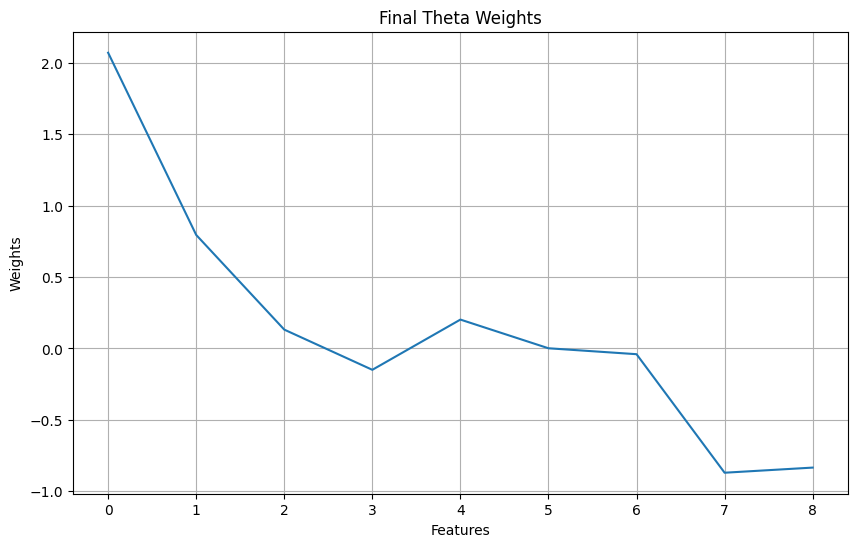

In [ ]:
#PLOT
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(theta_final)
plt.xlabel('Features')
plt.ylabel('Weights')
plt.title('Final Theta Weights')
plt.grid(True)
plt.show()

In [ ]:
# EVALUATE MODEL PERFORMANCE
X_tensor = tf.constant(X_test, dtype=tf.float32)
y_tensor = tf.constant(y_test.reshape(-1, 1), dtype=tf.float32)

# 1. Get Predictions
y_pred = tf.matmul(X_tensor, theta_final)

# 2. Calculate Mean Squared Error (MSE)
mse = tf.reduce_mean(tf.square(y_pred - y_tensor))

# 3. Calculate R-squared (R2 Score)
# Formula: 1 - (SS_res / SS_tot)
ss_res = tf.reduce_sum(tf.square(y_tensor - y_pred))
ss_tot = tf.reduce_sum(tf.square(y_tensor - tf.reduce_mean(y_tensor)))
r2_score = 1 - (ss_res / ss_tot)

print(f"Test MSE: {mse.numpy():.4f}")
print(f"Test R2 Score: {r2_score.numpy():.4f}")

Test MSE: 0.5471
Test R2 Score: 0.5825


In [ ]:
# DEBUGGING SHAPES
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"theta_final shape: {theta_final.shape}")

# Verification of the first few predictions vs actuals
y_pred_sample = tf.matmul(tf.constant(X_test[:5], dtype=tf.float32), theta_final)
print(f"\nSample Predictions:\n{y_pred_sample.numpy().flatten()}")
print(f"Sample Actuals:\n{y_test[:5]}")

X_train shape: (16512, 9)
y_train shape: (16512,)
theta_final shape: (9, 1)

Sample Predictions:
[0.7477118 1.7485635 2.599083  2.8402646 2.608403 ]
Sample Actuals:
[0.477   0.458   5.00001 2.186   2.78   ]


----
<br>

<br>
<br>

# --- MODULE 03: First Neural Network and Binary Classification ---

### **PART 4: FIRST NEURAL NETWORK**

In [ ]:
#LOAD THE DATA AND EXPLORE
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
#SPLIT THE DATA
X = df.drop('MedHouseVal', axis=1).values
y = df['MedHouseVal'].values

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#NORMALIZE THE DATA
from sklearn.preprocessing import StandardScaler
s_scaler = StandardScaler()
X_train = s_scaler.fit_transform(X_train)
X_test = s_scaler.transform(X_test)

#IMPORT
import tensorflow as tf
import keras

#BUILD A MODEL
model = keras.models.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(64, activation='relu'), #1 hidden layer
    keras.layers.Dense(32, activation='relu'), #2 hidden layer
    keras.layers.Dense(1) #output layer = Median house value

])

#COMPILE THE MODEL Optimizer='', loss = 'function', metrics=['']
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

#TRAIN THE MODEL  epoches, batch_size, validation_split
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.2)

Epoch 1/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.8877 - mae: 0.6598 - val_loss: 0.4934 - val_mae: 0.5030
Epoch 2/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4210 - mae: 0.4640 - val_loss: 0.4425 - val_mae: 0.4549
Epoch 3/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3781 - mae: 0.4377 - val_loss: 0.4011 - val_mae: 0.4628
Epoch 4/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3641 - mae: 0.4268 - val_loss: 0.3821 - val_mae: 0.4365
Epoch 5/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3492 - mae: 0.4173 - val_loss: 0.3742 - val_mae: 0.4410
Epoch 6/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3361 - mae: 0.4105 - val_loss: 0.3633 - val_mae: 0.4128
Epoch 7/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3298 - mae: 0.4032 - val_loss: 0.3507 - val_mae: 0.4087
Epoch 8/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3182 - mae: 0.3958 - val_loss: 0.3473 - val_mae: 0.4068
Epoch 9/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - lo

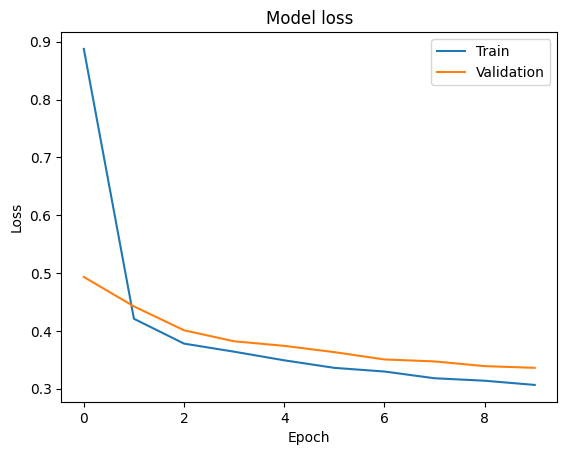

In [ ]:
#VISUALIZATION
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()

### **What is Batch Size?**

In your code, you set `batch_size=32`. Here is what that means for your model training:

1. **The Concept**: Instead of showing the model every single house in California one by one (which is slow) or all 16,000+ houses at once (which requires too much memory), we group them into small batches.
2. **The Update**: After the model processes **32 examples**, it calculates the average error (loss) for those 32 and updates its weights using Gradient Descent.
3. **Why 32?**: Smaller batches (like 32 or 64) are a good 'middle ground'. They provide enough data to get a good gradient direction but are small enough to fit in your computer's memory and add a bit of 'noise' that actually helps the model avoid getting stuck in local errors.

**In summary:**
* **1 Epoch**: One full pass through the entire dataset.
* **Batch Size**: How many samples the model 'digests' before making a correction.

### **What is Validation Split?**

In your code, you set `validation_split=0.2`. This tells Keras to set aside a portion of your training data to act as a "check-up" during training.

1. **The Partition**: It takes 20% of your training data and hides it from the model. The model never 'sees' this data during the weight update process.
2. **The Monitoring**: At the end of every epoch, the model makes predictions on this 20% and calculates the `val_loss` and `val_mae` (Mean Absolute Error).
3. **Why use it?**:
    * **Detect Overfitting**: If your `loss` (training) keeps going down but your `val_loss` starts going up, it means your model is just memorizing the training data and failing to generalize to new data.
    * **Early Stopping**: It helps you decide when to stop training before the model becomes too specialized to the training set.

**Key Difference:**
* **Training Loss**: How well the model is learning the data it's allowed to study.
* **Validation Loss**: How well the model is performing on data it hasn't studied yet (the "practice test").

### **Underfitting vs. Overfitting**

When training a neural network, we are looking for the "Goldilocks zone" where the model performs well on both training and validation data.

#### **1. Underfitting (The "Lazy" Model)**
* **What it is**: The model is too simple to learn the underlying patterns in the data.
* **How to spot it**: Both your **Training Loss** and **Validation Loss** are high, or they stop improving very early.
* **Analogy**: A student who doesn't study at all and fails both the practice tests and the final exam.
* **Fixes**: Increase model complexity (add more layers/neurons), train for more epochs, or reduce regularization.

#### **2. Overfitting (The "Memorizer")**
* **What it is**: The model learns the training data *too* well, including the noise and random fluctuations, but fails to generalize to new data.
* **How to spot it**: Your **Training Loss** keeps decreasing, but your **Validation Loss** starts to increase or stays significantly higher than the training loss.
* **Analogy**: A student who memorizes every specific question in the textbook but has no idea how to solve a slightly different version of the same problem.
* **Fixes**: Use more data, use **Dropout** layers, add **Regularization (L1/L2)**, or use **Early Stopping**.

#### **3. The Goal: Generalization**
We want a model where both losses are low and close to each other. This means the model has learned the actual patterns and can predict accurately on data it has never seen before.

In [ ]:
# Fix: Remove the extra bias column (added in a previous cell) if it exists
# The neural network expects 8 features, but X_test currently has 9.
if X_test.shape[1] == 9:
    X_test_eval = X_test[:, 1:]
else:
    X_test_eval = X_test

#EVALUATE THE MODEL
results = model.evaluate(X_test_eval, y_test)
print("Test Loss:", results[0])
print("Test MAE:", results[1])

predections = model.predict(X_test_eval)
print("\nSample Predictions:")
print(predections[:5].flatten())
print("Sample Actuals:")
print(y_test[:5])

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.3229 - mae: 0.3980
Test Loss: 0.3229089379310608
Test MAE: 0.3979514241218567
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 845us/step

Sample Predictions:
[0.6521599 1.4942666 4.379677  2.716072  3.014906 ]
Sample Actuals:
[0.477   0.458   5.00001 2.186   2.78   ]


----
<br>

### **PART 4: BINARY CLASSIFICATION**

In [ ]:
#BINARY CALSSIFICATION
#IMBD DATASET FOR : POSITIVE OR NEGATIVE
from tensorflow.keras.datasets import imdb

(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=10000)
print(train_data[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32]


In [ ]:
#DECODE THE TOKENISING IN ENGLISH
word_index = imdb.get_word_index()
reverse_word_index = dict([(value, key) for (key, value) in word_index.items()])

decoded_review = " ".join(
    [reverse_word_index.get(i - 3, "?") for i in train_data[0]]

)

decoded_review

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


"? this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert ? is an amazing actor and now the same being director ? father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for ? and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also ? to the two little boy's that played the ? of norman and paul they were just brilliant children are often left out of the ? list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for what they have done don't you th

In [ ]:
#MULTIHOT ENCODING
import numpy as np


def vectorize_sequence(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.
    return results

X_test = vectorize_sequence(test_data)
X_train = vectorize_sequence(train_data)
X_train

array([[0., 1., 1., ..., 0., 0., 0.],
       [0., 1., 1., ..., 0., 0., 0.],
       [0., 1., 1., ..., 0., 0., 0.],
       ...,
       [0., 1., 1., ..., 0., 0., 0.],
       [0., 1., 1., ..., 0., 0., 0.],
       [0., 1., 1., ..., 0., 0., 0.]])

In [ ]:
y_train = np.asarray(train_labels).astype("float32")
y_test = np.asarray(test_labels).astype("float32")
print(y_train[0])

1.0


In [ ]:
import keras
from keras import layers
from keras.callbacks import EarlyStopping

# 1. BUILD THE OPTIMIZED MODEL
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.5), # Helps prevent overfitting
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

# 2. COMPILE
model.compile(
    optimizer='rmsprop',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 3. DEFINE EARLY STOPPING
# This stops training when validation loss stops improving
callbacks = [
    EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)
]

# 4. TRAIN
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=512,
    validation_split=0.2,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.6282 - loss: 0.6297 - val_accuracy: 0.8346 - val_loss: 0.5022
Epoch 2/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.7674 - loss: 0.5079 - val_accuracy: 0.8704 - val_loss: 0.3924
Epoch 3/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.8285 - loss: 0.4186 - val_accuracy: 0.8880 - val_loss: 0.3223
Epoch 4/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.8619 - loss: 0.3611 - val_accuracy: 0.8912 - val_loss: 0.2888
Epoch 5/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.8856 - loss: 0.3111 - val_accuracy: 0.8880 - val_loss: 0.2868
Epoch 6/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.9003 - loss: 0.2828 - val_accuracy: 0.8942 - val_loss: 0.2683
Epoch 7/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9140 - loss: 0.2504 - val_accuracy: 0.8916 - val_loss: 0.2771
Epoch 8/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9223 - loss: 0.2248 - val_accuracy: 0.8946 - v

In [ ]:
history_dict = history.history
history_dict.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

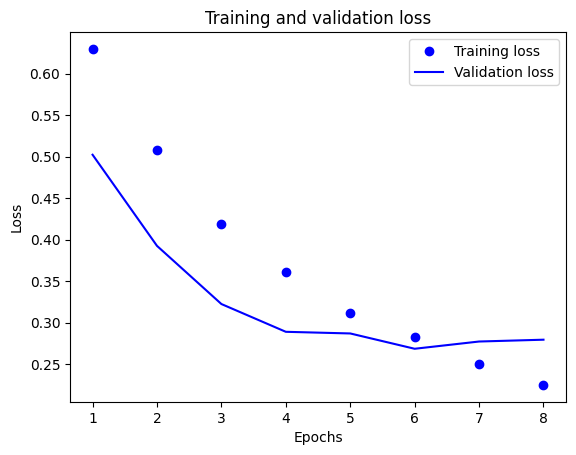

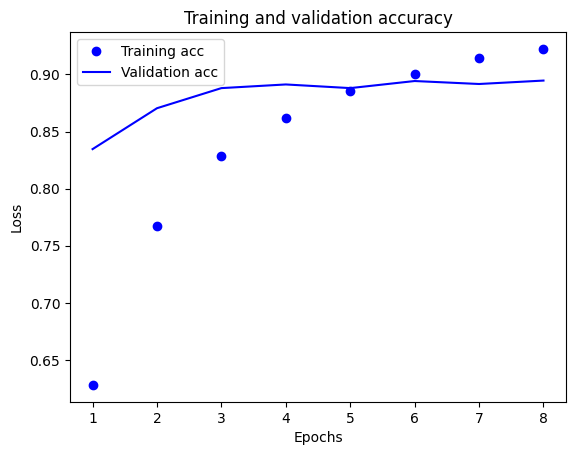

In [ ]:
#VISUALIZATION
import matplotlib.pyplot as plt

history_dict = history.history
Loss_values = history_dict['loss']
val_loss_values = history_dict['val_loss']
epoches = range(1, len(Loss_values) + 1)


plt.plot(epoches, Loss_values, 'bo', label='Training loss')
plt.plot(epoches, val_loss_values, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()


plt.clf()
acc = history_dict['accuracy']
val_acc = history_dict['val_accuracy']

plt.plot(epoches, acc, 'bo', label='Training acc')
plt.plot(epoches, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

In [ ]:
#EVALUATE MODEL
results = model.evaluate(X_test, y_test)

#PREDICTION
predictions = model.predict(X_test)
print(predictions[0])
print(y_test[0])

782/782 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8825 - loss: 0.2868
782/782 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
[0.1603243]
0.0


In [ ]:
print(predictions[0][0])

0.1603243


----
<br>

-----
### **PRATICE QUESTION**
-----

Training data shape: (455, 30)
Prediction targets (0 = Malignant, 1 = Benign): [0 1]


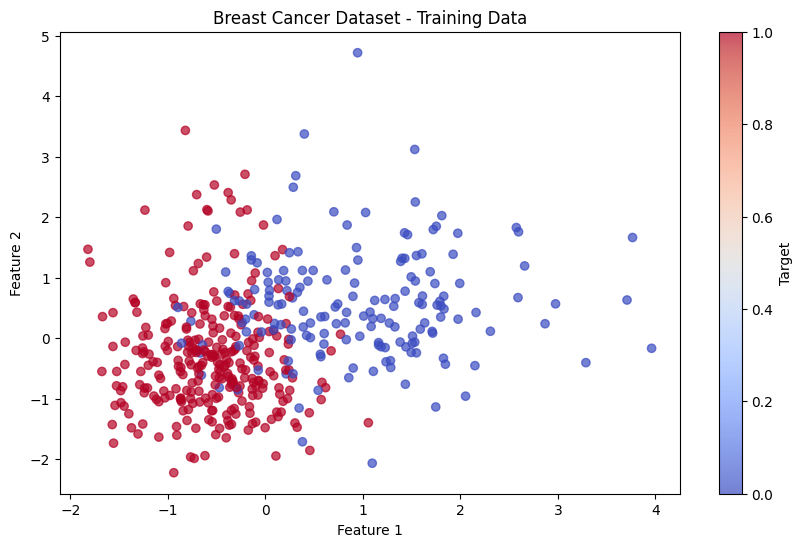

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# 1. Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target

# 2. Split into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Normalize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f"Training data shape: {X_train.shape}")
print(f"Prediction targets (0 = Malignant, 1 = Benign): {np.unique(y_train)}")

plt.figure(figsize=(10, 6))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', alpha=0.7)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Breast Cancer Dataset - Training Data')
plt.colorbar(label='Target')
plt.show()

In [ ]:
import keras
from keras import layers
from keras.callbacks import EarlyStopping

# 1. BUILD THE OPTIMIZED MODEL
modX = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),  # Regularization to prevent overfitting
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')
])

# 2. COMPILE
modX.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 3. DEFINE EARLY STOPPING
# Restores the weights from the best epoch to avoid using an overfitted final state
callbacks = [
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
]

# 4. TRAIN
history = modX.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.4148 - loss: 0.7331 - val_accuracy: 0.3956 - val_loss: 0.6727
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5357 - loss: 0.6252 - val_accuracy: 0.5714 - val_loss: 0.5842
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7088 - loss: 0.5254 - val_accuracy: 0.8681 - val_loss: 0.4835
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8764 - loss: 0.4204 - val_accuracy: 0.9121 - val_loss: 0.3710
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9148 - loss: 0.3359 - val_accuracy: 0.9231 - val_loss: 0.2897
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9341 - loss: 0.2682 - val_accuracy: 0.9341 - val_loss: 0.2391
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9396 - loss: 0.2290 - val_accuracy: 0.9341 - val_loss: 0.2050
Epoch 8/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9258 - loss: 0.2203 - val_accuracy: 0.9451 - val_loss

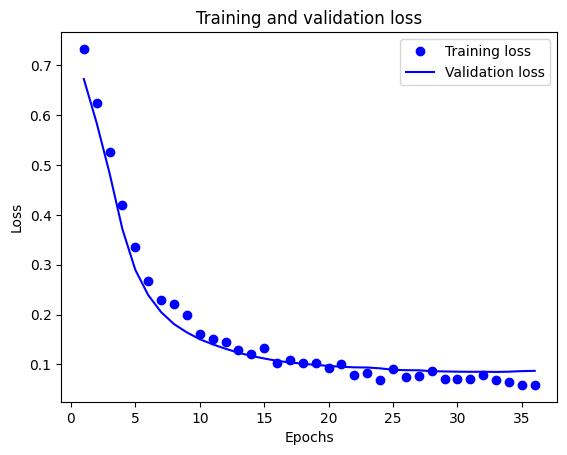

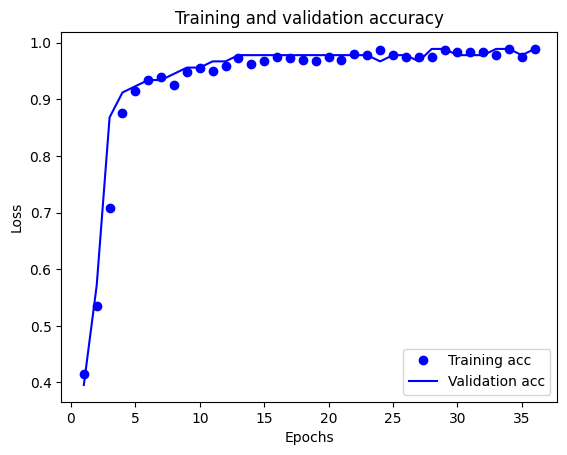

In [ ]:
#VISUALIZATION
import matplotlib.pyplot as plt

history_dict = history.history
history_dict.keys()

Loss_values = history_dict['loss']
val_loss_values = history_dict['val_loss']
epoches = range(1, len(Loss_values) + 1)

plt.plot(epoches, Loss_values, 'bo', label='Training loss')
plt.plot(epoches, val_loss_values, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

plt.clf()
acc = history_dict['accuracy']
val_acc = history_dict['val_accuracy']

plt.plot(epoches, acc, 'bo', label='Training acc')
plt.plot(epoches, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()


Test Loss: 0.0696
Test Accuracy: 0.9561

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


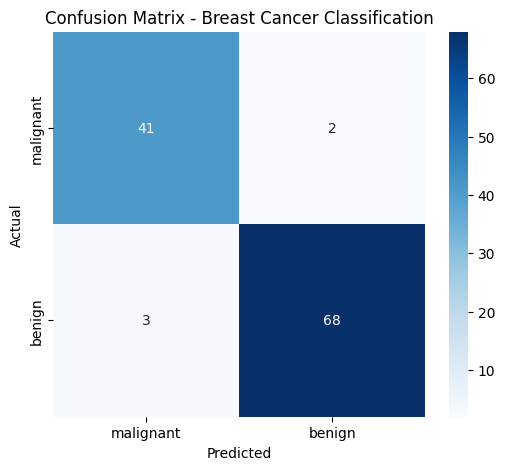


Detailed Classification Report:
              precision    recall  f1-score   support

   malignant       0.93      0.95      0.94        43
      benign       0.97      0.96      0.96        71

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



In [ ]:
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# 1. EVALUATE ON TEST SET
results = modX.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss: {results[0]:.4f}")
print(f"Test Accuracy: {results[1]:.4f}\n")

# 2. GENERATE PREDICTIONS
y_pred = (modX.predict(X_test) > 0.5).astype("int32")

# 3. VISUALIZE CONFUSION MATRIX
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=data.target_names, yticklabels=data.target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Breast Cancer Classification')
plt.show()

# 4. DETAILED REPORT
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))

### **Data Scientist's Approach: Advanced Evaluation & Best Practices**

Target Distribution: 1    0.627417
0    0.372583
Name: proportion, dtype: float64


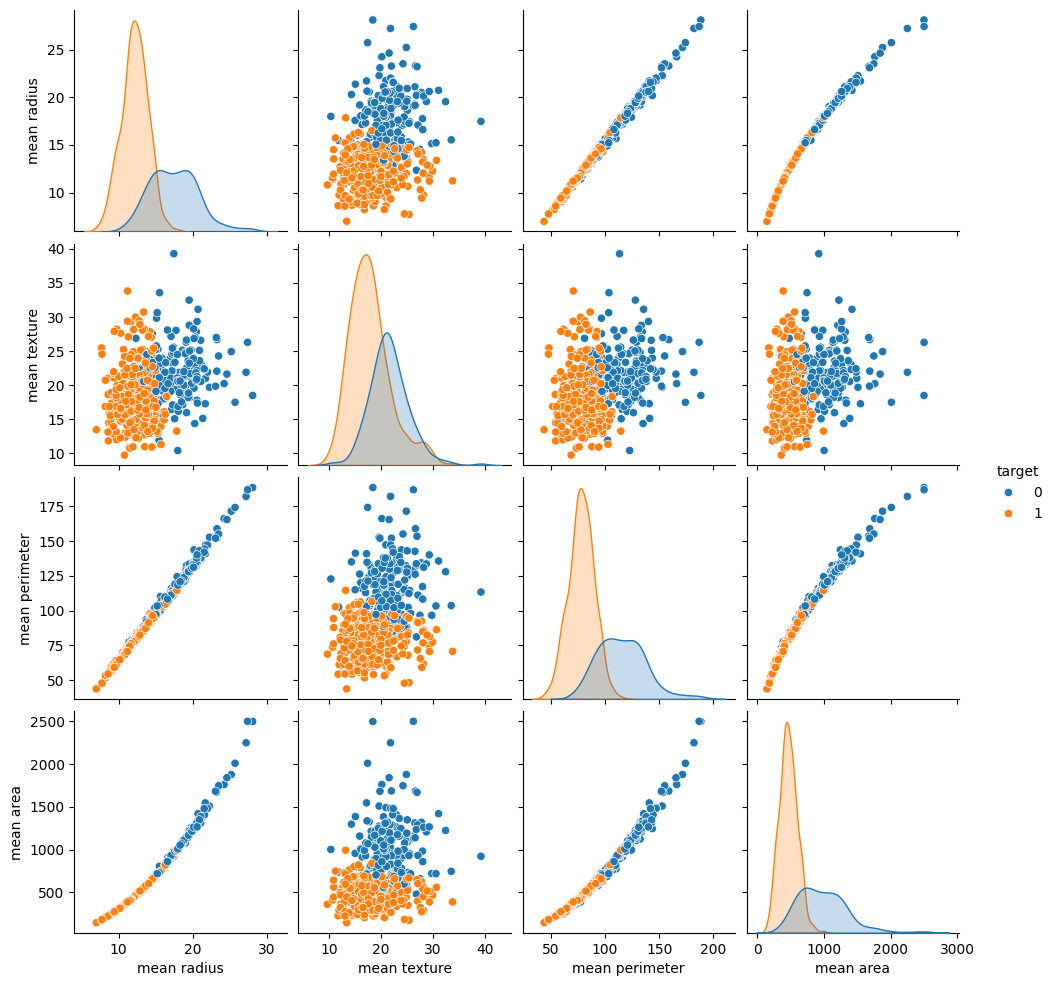

In [ ]:
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Professional Data Inspection
df_features = pd.DataFrame(data.data, columns=data.feature_names)
print(f"Target Distribution: {pd.Series(y).value_counts(normalize=True)}")

# Let's visualize the first few features to check for separability
sns.pairplot(pd.concat([df_features.iloc[:, :4], pd.Series(y, name='target')], axis=1), hue='target')
plt.show()

In [ ]:
# 2. Robust Model Building with Dropout and Early Stopping
model_pro = keras.models.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dropout(0.2),  # Regularization
    keras.layers.Dense(16, activation='relu'),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(1, activation='sigmoid')
])

model_pro.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Adding Early Stopping to stop training when val_loss stops improving
callback = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history_pro = model_pro.fit(
    X_train, y_train,
    epochs=50,
    validation_split=0.2,
    callbacks=[callback],
    verbose=0
)
print("Professional model training complete.")

Professional model training complete.


1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


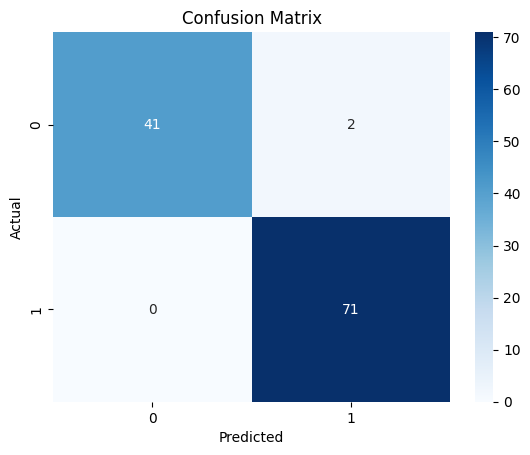


Detailed Classification Report:
              precision    recall  f1-score   support

   malignant       1.00      0.95      0.98        43
      benign       0.97      1.00      0.99        71

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [ ]:
# 3. Deep Evaluation: Confusion Matrix
y_pred_pro = (model_pro.predict(X_test) > 0.5).astype("int32")

cm = confusion_matrix(y_test, y_pred_pro)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred_pro, target_names=data.target_names))

<br>
<br>

# --- MODULE 04: Multiclass Classification and MNIST ---

### **PART 5: SINGLE LABEL CLASSIFICATION**

In [ ]:
from tensorflow.keras.datasets import reuters

(train_data, train_labels), (test_data, test_labels) = reuters.load_data(num_words=10000)
print(train_data[0])

2110848/2110848 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
[1, 2, 2, 8, 43, 10, 447, 5, 25, 207, 270, 5, 3095, 111, 16, 369, 186, 90, 67, 7, 89, 5, 19, 102, 6, 19, 124, 15, 90, 67, 84, 22, 482, 26, 7, 48, 4, 49, 8, 864, 39, 209, 154, 6, 151, 6, 83, 11, 15, 22, 155, 11, 15, 7, 48, 9, 4579, 1005, 504, 6, 258, 6, 272, 11, 15, 22, 134, 44, 11, 15, 16, 8, 197, 1245, 90, 67, 52, 29, 209, 30, 32, 132, 6, 109, 15, 17, 12]


In [ ]:
#MULTI HOT CODING
import numpy as np

def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.
    return results

X_train = vectorize_sequences(train_data)
X_test = vectorize_sequences(test_data)
X_train.shape

(8982, 10000)

In [ ]:
#Optional ! : One Hot Encoding
from tensorflow.keras.utils import to_categorical

one_hot_train_labels = to_categorical(train_labels)
one_hot_test_labels = to_categorical(test_labels)
one_hot_train_labels[0]

array([0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

Epoch 1/9
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 111ms/step - accuracy: 0.3158 - loss: 27.3192 - val_accuracy: 0.4491 - val_loss: 15.9949
Epoch 2/9
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.4536 - loss: 13.5814 - val_accuracy: 0.4630 - val_loss: 11.7690
Epoch 3/9
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.4725 - loss: 10.8423 - val_accuracy: 0.4830 - val_loss: 9.6267
Epoch 4/9
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.5042 - loss: 8.8577 - val_accuracy: 0.5147 - val_loss: 7.9671
Epoch 5/9
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.5197 - loss: 7.4213 - val_accuracy: 0.5237 - val_loss: 6.7555
Epoch 6/9
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.5184 - loss: 6.3271 - val_accuracy: 0.5314 - val_loss: 5.7978
Epoch 7/9
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.5278 - loss: 5.4579 - val_accuracy: 0.5270 - val_loss: 5.0386
Epoch 8/9
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.5282 - loss: 4.7675 - val_accuracy: 0.5287 - val

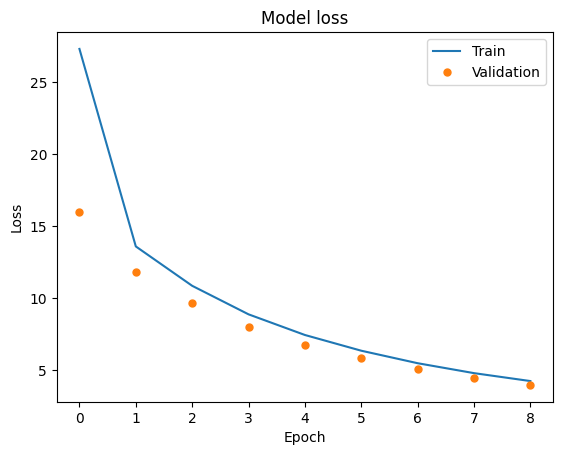

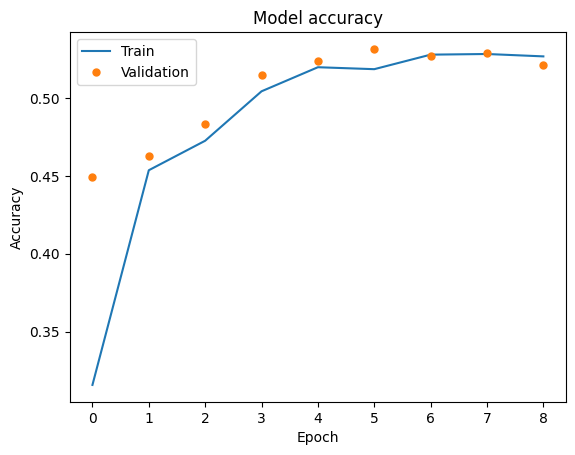

In [ ]:
import keras
from keras import regularizers, layers
mod = keras.models.Sequential([
    layers.Dense(64, activation='relu', kernel_regularizer=keras.regularizers.l2(0.2)),
    layers.Dense(32, activation='relu', kernel_regularizer=keras.regularizers.l2(0.2)),
    layers.Dense(16, activation='softmax')
])

mod.compile(optimizer='adam',  loss='sparse_categorical_crossentropy', metrics=['accuracy'])

hist = mod.fit(X_train, train_labels, epochs=9, batch_size=512, validation_split=0.2)
import matplotlib.pyplot as plt

plt.plot(hist.history['loss'])
plt.plot(hist.history['val_loss'], '.', markersize=10)
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()

plt.plot(hist.history['accuracy'])
plt.plot(hist.history['val_accuracy'], '.', markersize=10)
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
import numpy as np

eval_results = mod.evaluate(X_test, test_labels, verbose=0)
print(f"\nTest Loss: {eval_results[0]:.4f}")
print(f"Test Accuracy: {eval_results[1]:.4f}")

predx = mod.predict(X_test)

# Get the predicted class for the first sample
predicted_class_index = np.argmax(predx[0])
predicted_probability = predx[0][predicted_class_index]

print(f"\nPredicted probabilities for the first test sample (rounded to 2 decimal places):\n{predx[0].round(2)}")
print(f"Predicted class for the first test sample: {predicted_class_index} (with probability {predicted_probability:.2f})")
print(f"Actual label for the first test sample: {test_labels[0]}")


Test Loss: 3.9544
Test Accuracy: 0.5285
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

Predicted probabilities for the first test sample (rounded to 2 decimal places):
[0.   0.03 0.   0.45 0.3  0.   0.   0.   0.01 0.01 0.01 0.02 0.   0.01
 0.   0.   0.03 0.   0.   0.03 0.02 0.01 0.   0.   0.   0.01 0.   0.
 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
 0.   0.   0.   0.  ]
Predicted class for the first test sample: 3 (with probability 0.45)
Actual label for the first test sample: 3


----
<br>

### **MINST DIGIT VIEWER**

In [ ]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist

(c_train, d_train), (c_test, d_test) = mnist.load_data()
c_train[0]

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 170,
        253, 253, 253, 253, 253, 225, 172, 253, 242, 195,  64,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  49, 238, 253, 253, 253, 253,
        253, 253, 253, 253, 251,  93,  82,  82,  56,  39,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  18, 219, 253, 253, 253, 253,
        253, 198, 182, 247, 241,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  80, 156, 107, 253, 253,
        205,  11,   0,  43, 154,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,  14,   1, 154, 253,
         90,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 139, 253,
        190,   2,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  11, 190,
        253,  70,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  35,
        241, 225, 160, 108,   1,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         81, 240, 253, 253, 119,  25,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  45, 186, 253, 253, 150,  27,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,  16,  93, 252, 253, 187,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 249, 253, 249,  64,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  46, 130, 183, 253, 253, 207,   2,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  39,
        148, 229, 253, 253, 253, 250, 182,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  24, 114, 221,
        253, 253, 253, 253, 201,  78,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  23,  66, 213, 253, 253,
        253, 253, 198,  81,   2,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,  18, 171, 219, 253, 253, 253, 253,
        195,  80,   9,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,  55, 172, 226, 253, 253, 253, 253, 244, 133,
         11,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0, 136, 253, 25

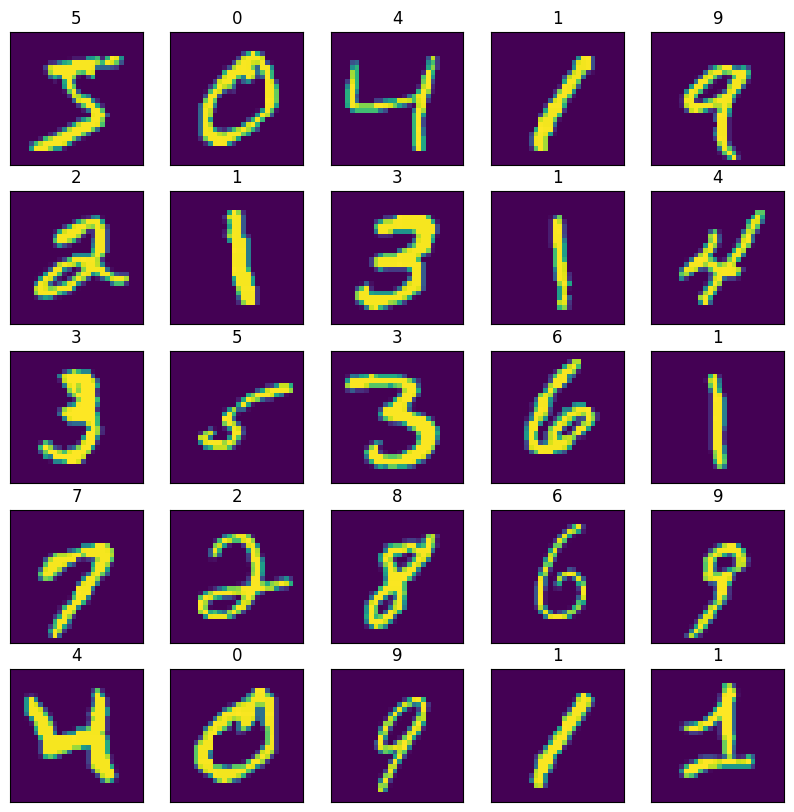

In [ ]:
import matplotlib.pyplot as plt

#VISUALIZE
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(c_train[i])
    plt.title(str(d_train[i])) # Add the digit as a title
plt.show()

## **reshape(-1, 28, 28, 1)**

          -1      28      28    1
           │       │       │
           │       │       └── Width (columns)
           │       └────────── Height (rows)
           └────────────────── Number of images
                               (calculated automatically)

In [ ]:
#NORMALIZE THE PIXWL VALUE FROM RANGE [0,1]
c_train, c_test = c_train / 255, c_test / 255

In [ ]:
#FLATTEN THE IMGES BY 28x28 INTO MATRICES
c_train = c_train.reshape(c_train.shape[0], 28, 28, 1)
c_test = c_test.reshape(c_test.shape[0], 28, 28, 1)
c_train[0]

array([[[0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ]],

       [[0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        

In [ ]:
import keras
from keras import layers
import tensorflow as tf

# SIMPLE DENSE MODEL (No Conv2D or MaxPooling)
model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Flatten(),              # This turns the 28x28 image into a 784-length vector
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Display model summary
model.summary()

# Train the model
hisx = model.fit(c_train, d_train, epochs=5, batch_size=64, validation_split=0.2)

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9094 - loss: 0.3137 - val_accuracy: 0.9528 - val_loss: 0.1573
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9620 - loss: 0.1266 - val_accuracy: 0.9661 - val_loss: 0.1213
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9730 - loss: 0.0877 - val_accuracy: 0.9707 - val_loss: 0.0950
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9789 - loss: 0.0667 - val_accuracy: 0.9726 - val_loss: 0.0910
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9847 - loss: 0.0503 - val_accuracy: 0.9727 - val_loss: 0.0880


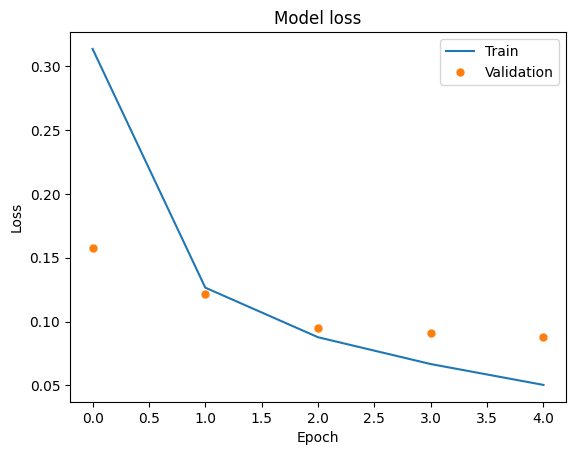

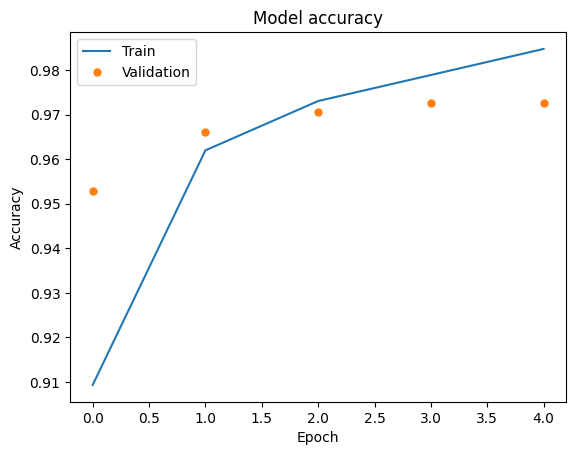

In [ ]:
plt.plot(hisx.history['loss'])
plt.plot(hisx.history['val_loss'], '.', markersize=10)
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()

plt.plot(hisx.history['accuracy'])
plt.plot(hisx.history['val_accuracy'], '.', markersize=10)
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(c_test, d_test)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9747 - loss: 0.0814

Test Loss: 0.0814
Test Accuracy: 97.47%


----
<br>

### **PRATICE QUESTION**

### **Practice Question: Fashion MNIST**

**Goal:** Build a neural network to classify 10 different types of clothing.

**Categories:**
0: T-shirt/top, 1: Trouser, 2: Pullover, 3: Dress, 4: Coat, 5: Sandal, 6: Shirt, 7: Sneaker, 8: Bag, 9: Ankle boot

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


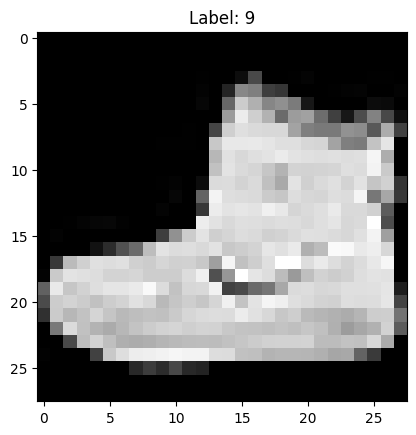

In [ ]:
import keras
from keras import layers
import matplotlib.pyplot as plt

# 1. Load the dataset
(f_train, l_train), (f_test, l_test) = keras.datasets.fashion_mnist.load_data()

# 2. Normalize
f_train, f_test = f_train / 255.0, f_test / 255.0

# 3. Visualize one sample to see what we are working with
plt.imshow(f_train[0], cmap='gray')
plt.title(f"Label: {l_train[0]}")
plt.show()

# --- YOUR TURN: Build and train your model below ---

In [ ]:
#FLATTEN THE IMAGE INTO 28x28 MATRICS
f_train = f_train.reshape(f_train.shape[0], 28, 28, 1)
f_test = f_test.reshape(f_test.shape[0], 28, 28, 1)
f_train[0]

array([[[0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ]],

       [[0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        [0.        ],
        

In [ ]:
import tensorflow as tf
import keras
from keras import layers

# 1. CNN MODEL ARCHITECTURE & use Flatten()
shop = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, kernel_size=(3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

# 2. COMPILE
shop.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 3. FAST EARLY STOPPING
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

# 4. TRAIN WITH GPU OPTIMIZED BATCH SIZE
# Increasing batch_size to 512 for GPU speed
dictr = shop.fit(
    f_train,
    l_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping]
)

Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 40s 49ms/step - accuracy: 0.8253 - loss: 0.4981 - val_accuracy: 0.8658 - val_loss: 0.3455
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 32s 43ms/step - accuracy: 0.8765 - loss: 0.3395 - val_accuracy: 0.8840 - val_loss: 0.3088
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 43s 46ms/step - accuracy: 0.8902 - loss: 0.2992 - val_accuracy: 0.8922 - val_loss: 0.2883
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 40s 44ms/step - accuracy: 0.9017 - loss: 0.2646 - val_accuracy: 0.8993 - val_loss: 0.2724
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 33s 45ms/step - accuracy: 0.9056 - loss: 0.2467 - val_accuracy: 0.9028 - val_loss: 0.2669


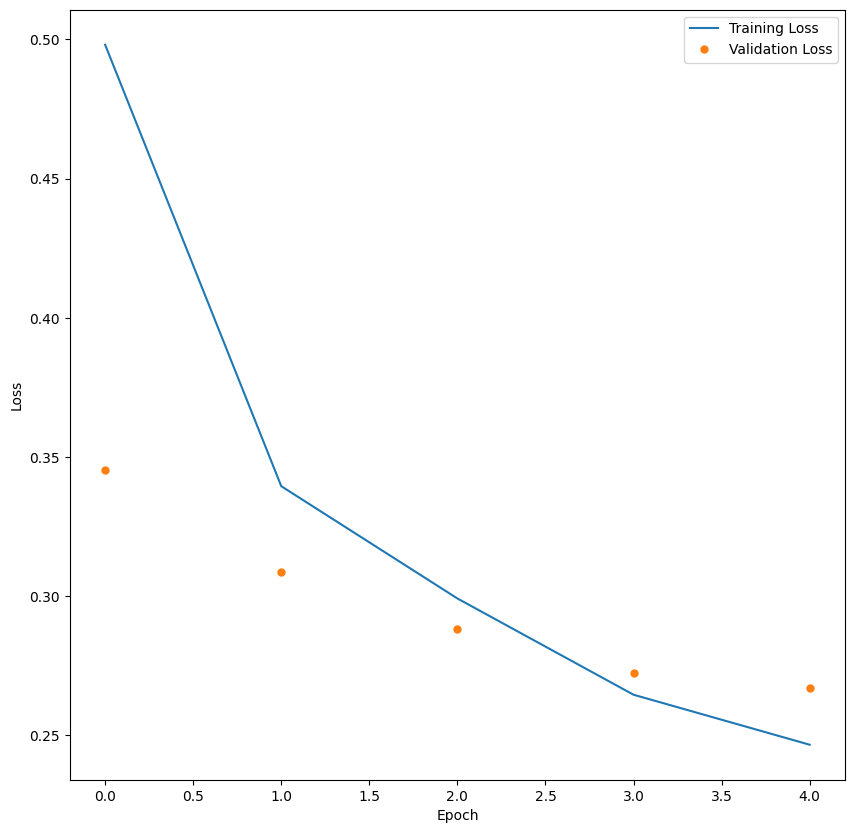

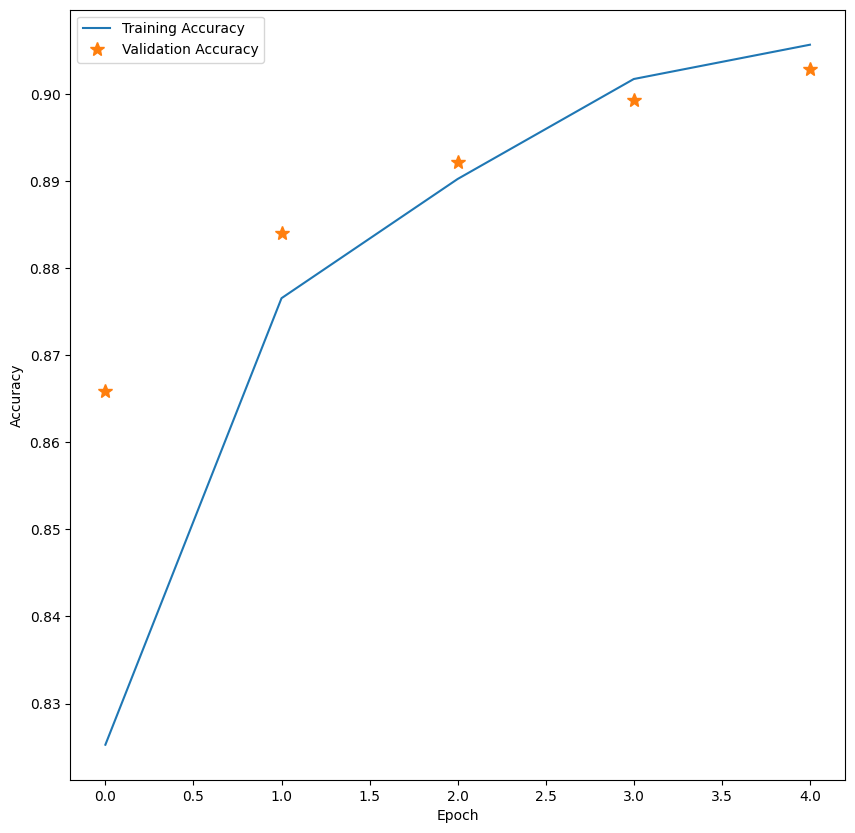

In [ ]:
plt.figure(figsize=(10, 10))
plt.plot(dictr.history['loss'], label='Training Loss')
plt.plot(dictr.history['val_loss'], '.', markersize=10, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Fixed the typo from 'accuraccy' to 'accuracy'
plt.figure(figsize=(10, 10))
plt.plot(dictr.history['accuracy'], label='Training Accuracy')
plt.plot(dictr.history['val_accuracy'], '*', markersize=10, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
# Use .evaluate() instead of .fit() for testing
eval_results = shop.evaluate(f_test, l_test, verbose=0)

# eval_results[0] is Loss, eval_results[1] is Accuracy
print(f"\nTest Loss: {eval_results[0]:.4f}")
print(f"Test Accuracy: {eval_results[1] * 100:.2f}%")


Test Loss: 0.2798
Test Accuracy: 89.70%


----
<br>

<br>
<br>

# --- MODULE 05: Custom Models and Layers ---

### **PART 6: CUSTOME MODEL AND LAYERS**

### **Custom Layer Flow**

```text
          │
          ▼

+------------------------+
|       __init__()       |
|    Create Variables    |
+------------------------+

          │
          ▼

+------------------------+
|         build()        |
|     Create Weights     |
+------------------------+

          │
          ▼

+------------------------+
|        call()          |
|      Forward Pass      |
+------------------------+
```

### 3_STEP PROCESSES



1.   __init__
2.   build
3.   call



In [ ]:
import tensorflow as tf
from tensorflow import keras

# This layer is like a 'Copy and Tape' machine
class DumbLayers(keras.layers.Layer):
  def __init__(self):
    # This part just sets up the basic layer rules
    super(DumbLayers, self).__init__()

  def call(self, inputs):
    # Imagine 'inputs' is a piece of paper.
    # We take the paper, make a copy, and glue them together side-by-side.
    # Now our data is twice as wide as it was before!
    return tf.concat([inputs, inputs], axis = 1)

# We start with a row of 32 boxes
inputs = keras.Input(shape=(32,))

# Run our boxes through the 'Copy and Tape' layer
x = DumbLayers()(inputs)

# Build the model so we can look at the blueprint
model = keras.Model(inputs=inputs, outputs=x)

# Look! The summary shows 64 boxes now because 32 + 32 = 64.
model.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dumb_layers (DumbLayers)        │ (None, 64)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# This is our custom 'Magical Machine' (a Dense Layer)
class CustomDenseLayer(keras.layers.Layer):
  def __init__(self, units = 32, activation=None):
    # Tell the computer this is a real Keras machine
    super(CustomDenseLayer, self).__init__()
    # How many answers do we want? (32)
    self.units = units
    # Pick a 'flavor' for the answer (like ReLU)
    self.activation = keras.activations.get(activation)

  def build(self, input_shape):
    # This part builds the machine's brain pieces the first time you use it

    # Create 'Weights' - these are like 'importance knobs'
    # The machine turns these to decide which inputs are important
    self.w = self.add_weight(
        shape = (input_shape[-1], self.units),
        initializer = 'random_normal',
        trainable = True
    )

    # Create 'Bias' - this is like an 'extra boost'
    # It's a number we add at the end just to help the machine get the right answer
    self.b = self.add_weight(
        shape = (self.units,),
        initializer = 'zeros',
        trainable = True
    )

  def call(self, inputs):
    # This is the machine actually working!
    # It takes the input, multiplies it by the 'importance knobs',
    # and then adds the 'extra boost' (y = mx + b)
    return tf.matmul(inputs, self.w) + self.b

# Prepare some numbers to put into the machine
inputs = keras.Input(shape=(32,))

# Put our machine to work with 32 outputs and a ReLU flavor
x = CustomDenseLayer(32, activation='relu')(inputs)

# Make the final model so we can see it
model = keras.Model(inputs=inputs, outputs=x)

# Show the 'blueprint' of our machine
model.summary()

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ custom_dense_layer              │ (None, 32)             │         1,056 │
│ (CustomDenseLayer)              │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,056 (4.12 KB)

 Trainable params: 1,056 (4.12 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# This is our Big Machine made of smaller magical machines
class SimpleFeedFowardModel(keras.Model):
  def __init__(self):
    super(SimpleFeedFowardModel, self).__init__()
    # We create three smaller machines to live inside this big one
    # The first two use 32 'knobs' and have a ReLU flavor
    self.dense1 = CustomDenseLayer(32, activation='relu')
    self.dense2 = CustomDenseLayer(32, activation='relu')
    # The last one gives us 10 final numbers (the answers)
    self.dense3 = CustomDenseLayer(10)

  def call(self, inputs):
    # This is how the machines work together in a line:
    # 1. First machine takes the data
    x = self.dense1(inputs)
    # 2. Second machine takes the first one's answer and looks at it again
    x = self.dense2(x)
    # 3. Third machine gives us the final results!
    return self.dense3(x)

# Create our big model
model = SimpleFeedFowardModel()

# Get the model ready to learn
model.compile(
    optimizer = keras.optimizers.Adam(learning_rate=1e-3), # The 'Teacher' (Adam)
    loss = keras.losses.SparseCategoricalCrossentropy(from_logits=True), # How we measure mistakes
    metrics = ['accuracy'] # A scorecard to see how many we got right
)

# Show the blueprint of the whole team of machines
model.summary()

Model: "simple_feed_foward_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ custom_dense_layer_1            │ ?                      │   0 (unbuilt) │
│ (CustomDenseLayer)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ custom_dense_layer_2            │ ?                      │   0 (unbuilt) │
│ (CustomDenseLayer)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ custom_dense_layer_3            │ ?                      │   0 (unbuilt) │
│ (CustomDenseLayer)              │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

-----
### **PRATICE QUESTION**
-----

In [ ]:
import tensorflow as tf
import keras
from keras import layers

class ResidualDenseBlock(layers.Layer):
    def __init__(self, units=32, activation='relu', **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.activation = keras.activations.get(activation)

    def build(self, input_shape):
        # Create the weight matrix
        self.w = self.add_weight(
            shape=(input_shape[-1], self.units),
            initializer='random_normal',
            trainable=True,
            name="weights"
        )
        # Create the bias vector
        self.b = self.add_weight(
            shape=(self.units,),
            initializer='zeros',
            trainable=True,
            name="bias"
        )

    def call(self, inputs):
        # 1. Standard dense layer math: (X * W) + b
        dense_output = tf.matmul(inputs, self.w) + self.b

        # 2. Apply the activation function (ReLU)
        activated_output = self.activation(dense_output)

        # 3. The Residual Connection: Add the original inputs back!
        return activated_output + inputs

----
<br>

### **FUNCTIONAL MODELS API**

In [ ]:
import tensorflow as tf
from tensorflow import keras

#Create the inputs for the model
inputs = keras.Input(shape=(3,))
#Making The first Layer then adding inputs
x = keras.layers.Dense(4, activation='relu', name='Hidden_Layer_1')(inputs)
x = keras.layers.Dense(2, activation='relu', name='Hidden_Layer_2')(x)
outputs = keras.layers.Dense(1)(x)

model = keras.Model(inputs=inputs, outputs=outputs, name='Simple Model')

model.summary()

model.compile(optimizer='adam', loss='mse', metrics=['mae'])

Model: "Simple Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 3)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_1 (Dense)          │ (None, 4)              │            16 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_2 (Dense)          │ (None, 2)              │            10 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29 (116.00 B)

 Trainable params: 29 (116.00 B)

 Non-trainable params: 0 (0.00 B)

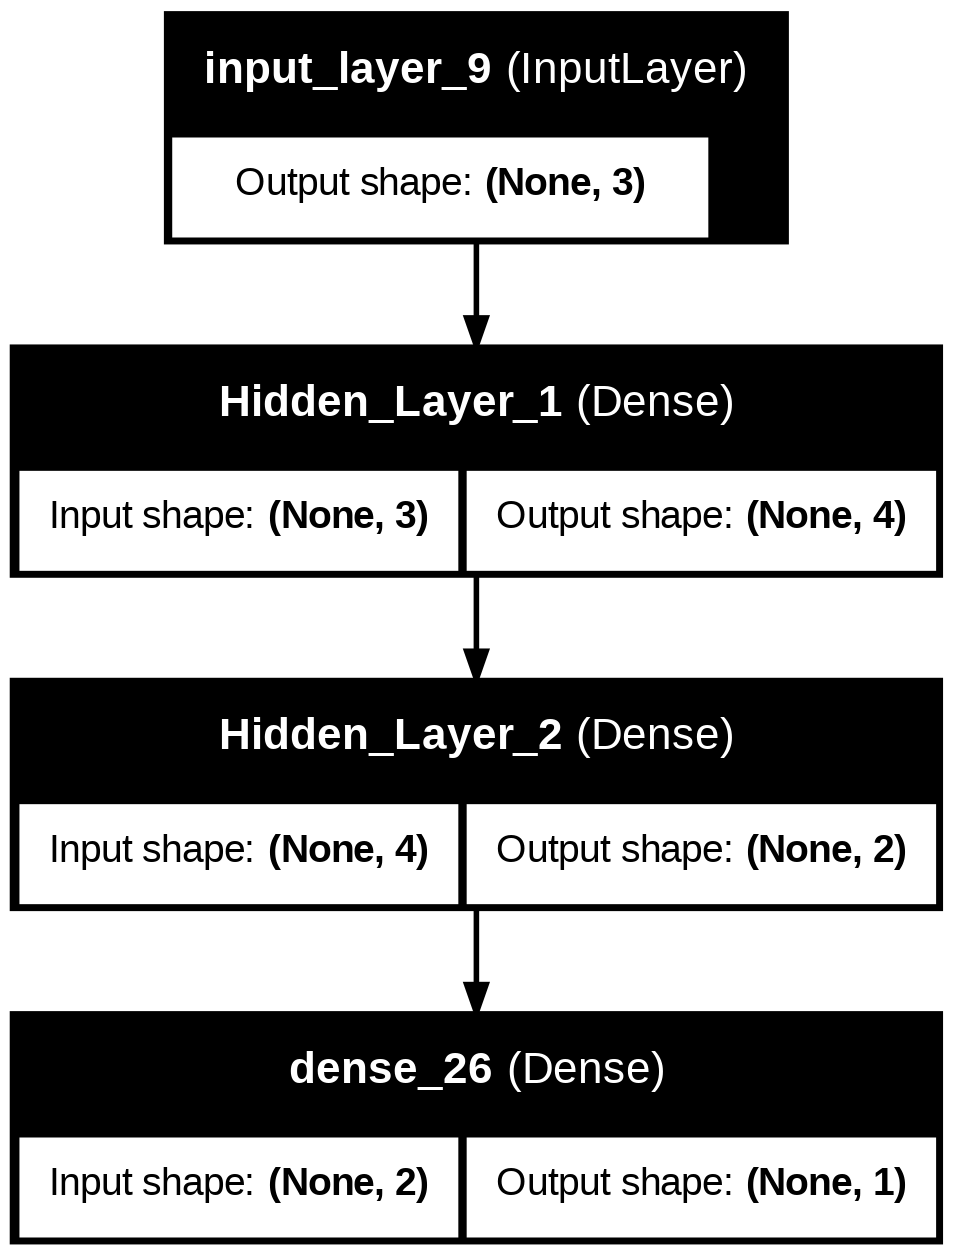

In [ ]:
keras.utils.plot_model(model, show_shapes=True, show_layer_names=True)

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Input_1             │ (None, 32)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_27 (Dense)    │ (None, 64)        │      2,112 │ Input_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_28 (Dense)    │ (None, 32)        │      2,080 │ dense_27[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 96)        │          0 │ dense_27[0][0],   │
│ (Concatenate)       │                   │            │ dense_28[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_31 (Dense)    │ (None, 64)        │      6,208 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_32 (Dense)    │ (None, 32)        │      2,080 │ dense_31[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Input_2             │ (None, 16)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_33 (Dense)    │ (None, 1)         │         33 │ dense_32[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 12,513 (48.88 KB)

 Trainable params: 12,513 (48.88 KB)

 Non-trainable params: 0 (0.00 B)

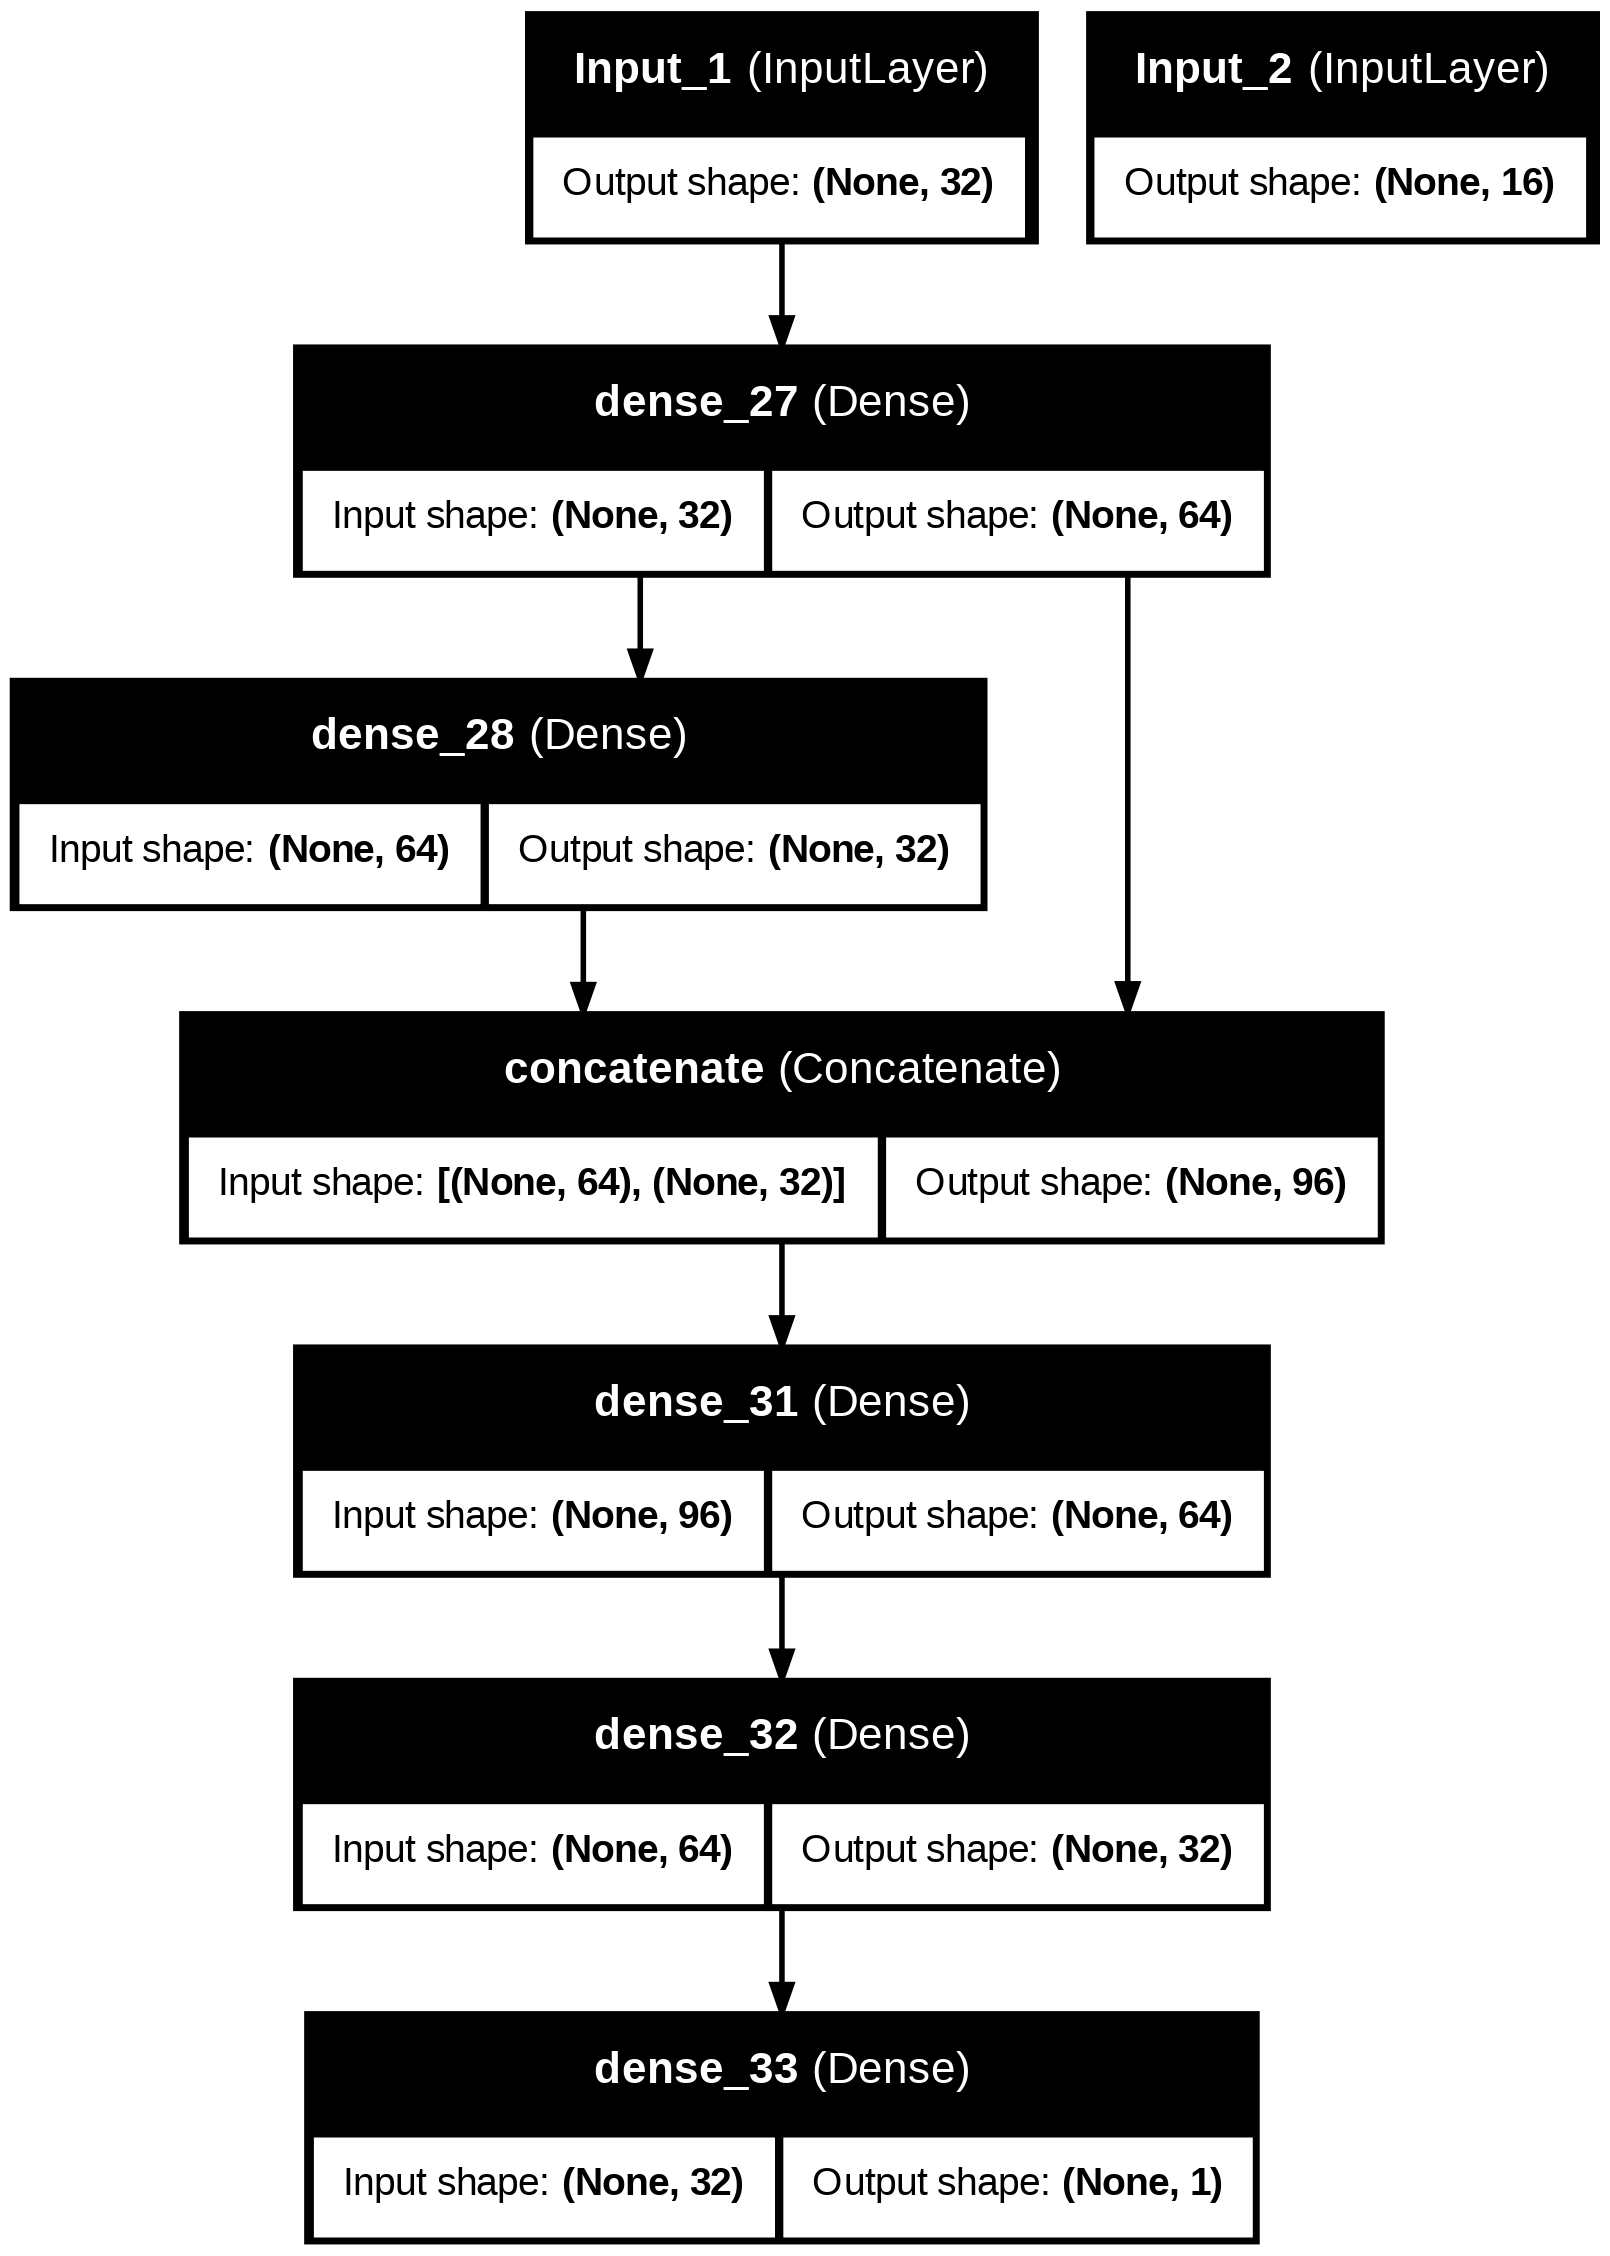

In [ ]:
from keras.layers import Input
from keras.models import Model
from keras.layers import Dense, Concatenate

#DEFINE THE FIRST INPUT AND ITS PROCESSING BRANCH
inputs_1 = Input(shape=(32,), name='Input_1')
x1 = Dense(64, activation='relu')(inputs_1)
x2 = Dense(32, activation='relu')(x1)

#DEFINE THE SECOND INPUT AND ITS PROCESSING BRANCH
inputs_2 = Input(shape=(16,), name='Input_2')
y1 = Dense(32, activation='relu')(inputs_2)
y2 = Dense(16, activation='relu')(y1)

#CONCATENATE THE PROCESSING BRANCHES
concatenated = Concatenate()([x1, x2])

#ADD SOME FULLY CONNECTED LAYERS AFTER MERGING
x = Dense(64, activation='relu')(concatenated)
x = Dense(32, activation='relu')(x)
outputs = Dense(1)(x)

#CREATE THE MODEL
model = Model(inputs=[inputs_1, inputs_2], outputs=outputs)

#COMPLIE MODEL
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

model.summary()
keras.utils.plot_model(model, show_shapes=True, show_layer_names=True)

### **Example: Multi-Input Ticket Classifier**
In this scenario, we imagine a system that receives:
1.  **Ticket Body**: Processed as a 10,000-word vector (like the IMDb example).
2.  **Metadata**: 10 features representing priority, department ID, etc.

The model will predict which of the **46 categories** (like the Reuters example) the ticket belongs to.

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ticket_body         │ (None, 10000)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ metadata            │ (None, 10)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_34 (Dense)    │ (None, 64)        │    640,064 │ ticket_body[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_35 (Dense)    │ (None, 32)        │        352 │ metadata[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 96)        │          0 │ dense_34[0][0],   │
│ (Concatenate)       │                   │            │ dense_35[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_36 (Dense)    │ (None, 64)        │      6,208 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ category_output     │ (None, 46)        │      2,990 │ dense_36[0][0]    │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 649,614 (2.48 MB)

 Trainable params: 649,614 (2.48 MB)

 Non-trainable params: 0 (0.00 B)

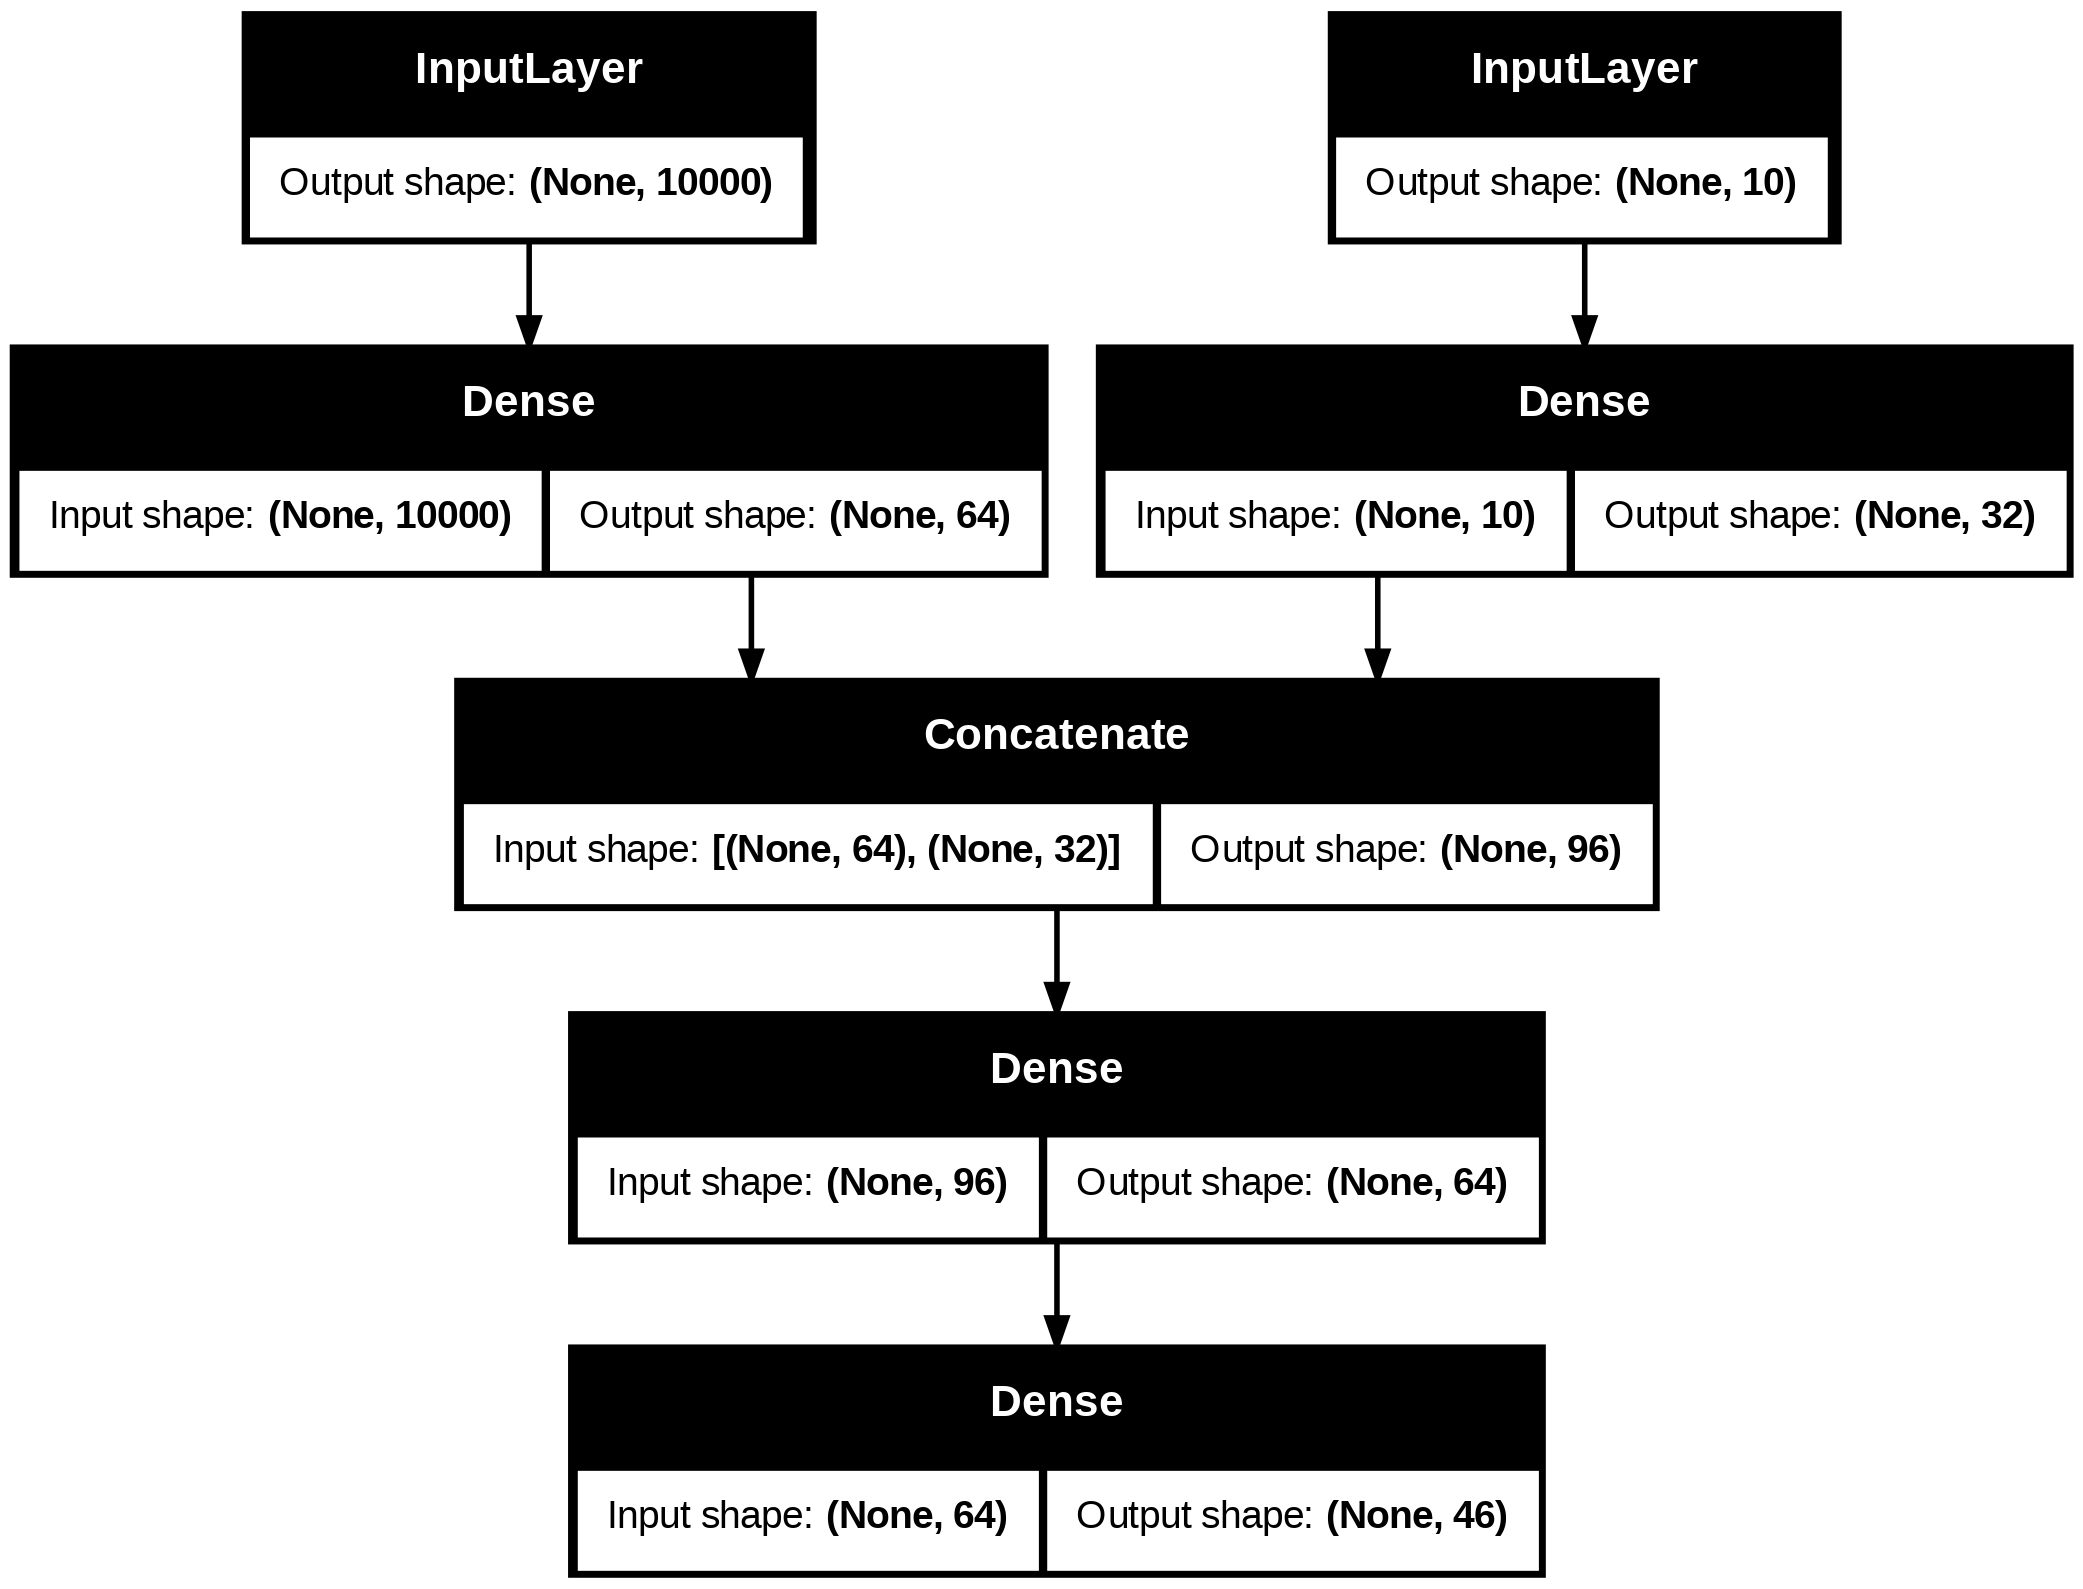

In [ ]:
from keras.layers import Input, Dense, Concatenate
from keras.models import Model

# 1. Branch for the Ticket Text (High-dimensional)
text_input = Input(shape=(10000,), name="ticket_body")
x = Dense(64, activation="relu")(text_input)

# 2. Branch for Metadata (Low-dimensional)
meta_input = Input(shape=(10,), name="metadata")
y = Dense(32, activation="relu")(meta_input)

# 3. Merge branches
merged = Concatenate()([x, y])

# 4. Final Classification Layers
z = Dense(64, activation="relu")(merged)
ticket_category = Dense(46, activation="softmax", name="category_output")(z)

# 5. Define Model
ticket_model = Model(inputs=[text_input, meta_input], outputs=ticket_category)

ticket_model.summary()
keras.utils.plot_model(ticket_model, show_shapes=True)

# **REWRITTEN: TICKET PROCESSING SYSTEM (COMPLETE WORKFLOW)**
This section provides the full code in a modular, step-by-step structure.

In [ ]:
import keras
from keras.layers import Input, Dense, Concatenate
from keras.models import Model
import numpy as np

# STEP 1: DEFINE THE ARCHITECTURE
# ------------------------------
# Branch A: Ticket Text (High-dimensional input)
text_input = Input(shape=(10000,), name="ticket_body")
x = Dense(64, activation="relu")(text_input)

# Branch B: Metadata (Low-dimensional input)
meta_input = Input(shape=(10,), name="metadata")
y = Dense(32, activation="relu")(meta_input)

# Merge and Final Classification
merged = Concatenate()([x, y])
z = Dense(64, activation="relu")(merged)
ticket_category = Dense(46, activation="softmax", name="category_output")(z)

# Construct Model
ticket_model = Model(inputs=[text_input, meta_input], outputs=ticket_category)

# STEP 2: COMPILE THE MODEL
# ------------------------------
ticket_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# STEP 3: DATA PREPARATION (Synthetic)
# ------------------------------
num_samples = 128
test_text = np.random.random((num_samples, 10000))
test_meta = np.random.random((num_samples, 10))
test_labels = np.random.randint(46, size=(num_samples,))

# STEP 4: TRAIN THE MODEL
# ------------------------------
print("Starting consolidated training run...")
history = ticket_model.fit(
    x={"ticket_body": test_text, "metadata": test_meta},
    y=test_labels,
    epochs=5,
    batch_size=32,
    verbose=1
)

print(f"\nTraining finished. Final Accuracy: {history.history['accuracy'][-1]:.4f}")

Starting consolidated training run...
Epoch 1/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.0312 - loss: 4.3170
Epoch 2/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.0469 - loss: 3.8865    
Epoch 3/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.0625 - loss: 3.7050
Epoch 4/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.0703 - loss: 3.6479
Epoch 5/5
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.0859 - loss: 3.5812

Training finished. Final Accuracy: 0.0859


-----
<br>

<br>
<br>

# --- MODULE 06: Callbacks, Regularization, and Saving ---

### **CALLBACKS AND MODEL SAVING**

### **Step 1: Setup Callbacks**
Callbacks are functions applied at specific stages of training, such as at the end of every epoch.

In [ ]:
from keras.callbacks import ModelCheckpoint, EarlyStopping

# 1. EarlyStopping: Stop if validation loss doesn't improve for 3 epochs
# 'restore_best_weights' ensures the model keeps the best version, not the last one
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# 2. ModelCheckpoint: Save the best model to a file automatically
checkpoint = ModelCheckpoint(
    filepath='best_ticket_model.keras',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

callbacks_list = [early_stop, checkpoint]

### **Step 2: Training with Callbacks**
Notice how we pass the `callbacks` list to the `.fit()` method.

In [ ]:
print("Training with callbacks...")
history = ticket_model.fit(
    x={"ticket_body": test_text, "metadata": test_meta},
    y=test_labels,
    epochs=20, # Higher epochs, but EarlyStopping will catch it
    batch_size=32,
    validation_split=0.2,
    callbacks=callbacks_list,
    verbose=1
)

Training with callbacks...
Epoch 1/20
1/4 ━━━━━━━━━━━━━━━━━━━━ 1s 376ms/step - accuracy: 0.3125 - loss: 3.4704
Epoch 1: val_accuracy improved from None to 0.11538, saving model to best_ticket_model.keras

Epoch 1: finished saving model to best_ticket_model.keras
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step - accuracy: 0.2059 - loss: 3.4983 - val_accuracy: 0.1154 - val_loss: 3.4109
Epoch 2/20
1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.3125 - loss: 3.3116
Epoch 2: val_accuracy did not improve from 0.11538
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.1373 - loss: 3.4086 - val_accuracy: 0.0385 - val_loss: 3.3243
Epoch 3/20
1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.1562 - loss: 3.1774
Epoch 3: val_accuracy did not improve from 0.11538
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.1765 - loss: 3.2802 - val_accuracy: 0.0385 - val_loss: 3.3348
Epoch 4/20
1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.1875 - loss: 3.1258
Epoch 4: val_accuracy did not improve from 0

### **Step 3: Manual Saving and Loading**
You can also save the model manually at any time.

In [ ]:
# Save the final model
ticket_model.save('final_ticket_model.keras')
print("Model saved to disk.")

# Load the model back
from keras.models import load_model
reloaded_model = load_model('final_ticket_model.keras')

# Verify it works
print("Model reloaded successfully.")
reloaded_model.summary()

Model saved to disk.
Model reloaded successfully.


Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ticket_body         │ (None, 10000)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ metadata            │ (None, 10)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_37 (Dense)    │ (None, 64)        │    640,064 │ ticket_body[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_38 (Dense)    │ (None, 32)        │        352 │ metadata[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 96)        │          0 │ dense_37[0][0],   │
│ (Concatenate)       │                   │            │ dense_38[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_39 (Dense)    │ (None, 64)        │      6,208 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ category_output     │ (None, 46)        │      2,990 │ dense_39[0][0]    │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,948,844 (7.43 MB)

 Trainable params: 649,614 (2.48 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,299,230 (4.96 MB)

----
<br>

### **REGULARIZATION**

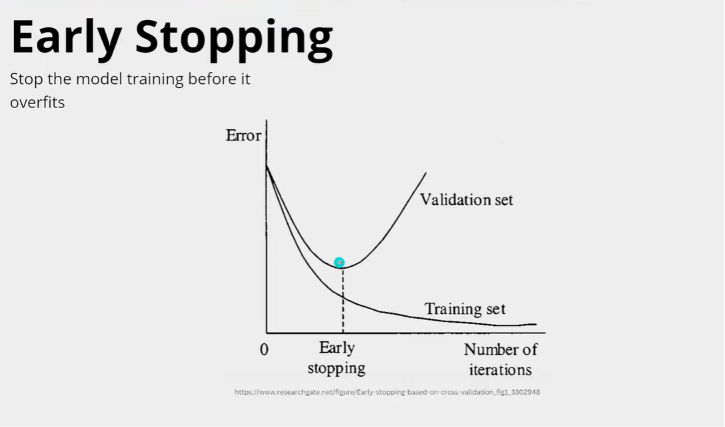

### **1. Dropout Regularization**
Dropout is one of the most effective and commonly used regularization techniques. During training, it randomly 'drops out' (sets to zero) a number of output features of the layer.

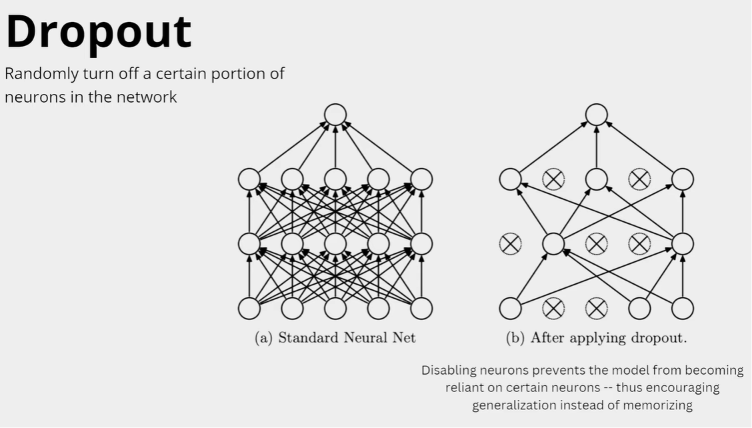

In [ ]:
from keras.layers import Dropout

# Adding Dropout to the Ticket Processing Model
text_input = Input(shape=(10000,), name="ticket_body")
x = Dense(64, activation="relu")(text_input)
x = Dropout(0.5)(x) # 50% of neurons are disabled every step

meta_input = Input(shape=(10,), name="metadata")
y = Dense(32, activation="relu")(meta_input)
y = Dropout(0.2)(y)

merged = Concatenate()([x, y])
z = Dense(64, activation="relu")(merged)
z = Dropout(0.3)(z)

ticket_category = Dense(46, activation="softmax")(z)

dropout_model = Model(inputs=[text_input, meta_input], outputs=ticket_category)
print("Model with Dropout layers created.")

Model with Dropout layers created.


### **2. Weight Regularization (L1 & L2)**
This adds a cost to the loss function associated with having large weights. This forces the model weights to take only small values, making the distribution of weight values more 'regular'.

In [ ]:
from keras import regularizers, layers
import keras

# 1. L2 Regularization (Weight Decay)
# penalty = 0.001 * weight_value^2
model_l2 = keras.Sequential([
    layers.Input(shape=(10000,)),
    layers.Dense(16,
                 kernel_regularizer=regularizers.l2(0.001),
                 activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

# 2. L1 Regularization (Lasso)
# penalty = 0.001 * |weight_value|
model_l1 = keras.Sequential([
    layers.Input(shape=(10000,)),
    layers.Dense(16,
                 kernel_regularizer=regularizers.l1(0.001),
                 activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model_l2.compile(optimizer="rmsprop", loss="binary_crossentropy", metrics=["accuracy"])
print("Regularized models compiled successfully.")

Regularized models compiled successfully.


### **3. L1 vs L2 vs ElasticNet**
- **L2 (Weight Decay):** Penalty = `λ * sum(weights^2)`. Keeps weights small.
- **L1 (Lasso):** Penalty = `λ * sum(|weights|)`. Can result in sparse weights (zeros).
- **ElasticNet:** Penalty = `L1 + L2`. Combines both benefits.

In [ ]:
from keras import regularizers, layers

# Example of ElasticNet (L1 and L2 together)
model_en = keras.Sequential([
    layers.Input(shape=(10000,)),
    layers.Dense(16,
                 kernel_regularizer=regularizers.L1L2(l1=0.001, l2=0.001),
                 activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model_en.compile(optimizer="rmsprop", loss="binary_crossentropy", metrics=["accuracy"])
print("ElasticNet model compiled successfully.")

ElasticNet model compiled successfully.


-----
<br>

<br>
<br>

# --- MODULE 07: Datasets ---

### **DATASETS**

In [ ]:
#CREATE DATASET USING THE TENSORFLOW
import tensorflow as tf
from tensorflow import keras

# Datasets
# Corrected: Pass a list [1, 2, ...] so TensorFlow can slice it into elements
dataset = tf.data.Dataset.from_tensor_slices([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])

# Convert to list of standard Python ints to verify contents without np.int prefix
print([int(x) for x in dataset.as_numpy_iterator()])

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


In [ ]:
#CREATE DATASET USING THE NUMPY
import numpy as np
data = np.array([1,2,3,4,5,6,7,8,9,10])
# Fixed: Dataset is singular, not plural
dataset = tf.data.Dataset.from_tensor_slices(data)
# Fixed: Corrected spelling of 'dataset'
list(dataset.as_numpy_iterator())

[np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(4),
 np.int64(5),
 np.int64(6),
 np.int64(7),
 np.int64(8),
 np.int64(9),
 np.int64(10)]

In [ ]:
#USING THE FEATURES AND LABELS
features = tf.constant([[1,2], [3,4], [5,6]])
# Fixed: spelling of labels
labels = tf.constant(['cat', 'dog', 'fox'])
# Fixed: using the correct variable name 'labels'
dataset = tf.data.Dataset.from_tensor_slices((features, labels))
# Fixed: using 'dataset' to match the variable above
list(dataset.as_numpy_iterator())

[(array([1, 2], dtype=int32), b'cat'),
 (array([3, 4], dtype=int32), b'dog'),
 (array([5, 6], dtype=int32), b'fox')]

### **PART 8: FINE-TUNING**

Once your model has converged with a new classifier, you can try unfreezing the top layers of the base model and training them as well. This is called **Fine-Tuning**.

**Steps for Fine-Tuning:**
1.  **Freeze** the base model and train the new head (already done).
2.  **Unfreeze** the base model.
3.  **Freeze** all layers except for the last few ones.
4.  **Recompile** the model with a very low learning rate (to avoid wrecking the pre-trained weights).
5.  **Continue training**.

### **Example: Unfreezing the Top Layers**

In [ ]:
base_model.trainable = True

# Let's see how many layers are in the base model
print("Number of layers in the base model: ", len(base_model.layers))

# Fine-tune from this layer onwards
fine_tune_at = 100

# Freeze all the layers before the `fine_tune_at` layer
for layer in base_model.layers[:fine_tune_at]:
  layer.trainable = False

# Recompile (Critical: use a much lower learning rate)
model.compile(
    loss='binary_crossentropy',
    optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.00001),
    metrics=['accuracy']
)

model.summary()

Number of layers in the base model:  154


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,862,721 (7.11 MB)

 Non-trainable params: 396,544 (1.51 MB)